---
# Aprendizaje no supervisado de datos biométricos de un smartwatch

**Evaluación Parcial 5 · Encargo Aprendizaje no supervisado**

---
### Integrantes:
- VINCENT FARENDEN CERÓN
- RODRIGO IGNACIO MARTÍNEZ BECKER
- DIEGO IGNACIO PEÑA Y LILLO LUHRS

### Asignatura:
- MACHINE LEARNING_001D

### Profesor:
- FRANCISCO JAVIER JEREZ SALAZAR

### Fecha:
- 22-11-2026

---

## Introducción y objetivo del informe

Este informe corresponde a la tercera entrega del proyecto semestral. En la Evaluación
Parcial 1 se limpió y preparó un conjunto de 10.000 registros biométricos capturados por un
smartwatch (`01_limpieza_health_data.ipynb`), y en la Evaluación Parcial 3 se entrenaron
modelos supervisados sobre esos datos (`02_modelamiento_supervisado.ipynb`), con un resultado
concluyente: ninguna medición permite predecir a otra.

En esta etapa la pregunta cambia. Ya no se busca predecir una variable a partir de las
demás, sino descubrir si los registros se organizan en **grupos naturales**: perfiles de
medición con combinaciones parecidas de pulso, oxigenación, pasos, sueño, actividad y estrés,
que permitan **segmentar a los usuarios** del dispositivo (por ejemplo, para personalizar
recomendaciones o priorizar alertas) sin necesidad de una variable objetivo.

El resultado de la EP3 no responde por sí solo esta pregunta. La correlación y los modelos
supervisados miden si una variable depende de otras; un agrupamiento, en cambio, puede
aparecer como una combinación de valores que se repite en el espacio de todas las variables
a la vez, aunque ninguna variable prediga a otra. Por eso el análisis se plantea como una
prueba y no como una conclusión anticipada.

| Pregunta | Técnica | Apartado |
| --- | --- | --- |
| ¿Qué variables aportan información para segmentar? | Filtros de selección de características | 2 |
| ¿Se puede representar el conjunto en menos dimensiones sin perder información? | PCA (lineal) y t-SNE (no lineal) | 3 |
| ¿Existen grupos de registros con perfiles distintos? | K-Means, jerárquico aglomerativo y DBSCAN | 4 |
| ¿Qué representa cada grupo en el mundo real? | Perfil de los grupos de K-Means | 5 |
| ¿Son grupos reales o un artefacto del algoritmo? | Silhouette, Calinski-Harabasz y Davies-Bouldin, contrastados con una referencia sin estructura y un control positivo | 6 y 7 |

### Correspondencia con el encargo

| Apartado del encargo | Indicador | Dónde se desarrolla |
| --- | --- | --- |
| Selección de características: variables conservadas y descartadas | IE2 | 2 › Filtros 1 a 3 y Variables conservadas y descartadas |
| Dos algoritmos de reducción de dimensionalidad (lineal y no lineal) y descripción del resultado | IE1 | 3 › PCA y t-SNE, cada uno con la lectura de su resultado, y Síntesis |
| Tres algoritmos de agrupamiento con exploración de hiperparámetros | IE3 | 4 › K-Means (`k`, `init`, `n_init`), jerárquico aglomerativo (enlace y `k`) y DBSCAN (`eps` y `min_samples`) |
| Significado de cada grupo en el mundo real | IE4 | 5 › Perfil de los grupos y Descripción de los grupos |
| Índices de validación interna | IE5 | 6 › Índices de las configuraciones seleccionadas, Silueta por registro, Valores de referencia y Origen de los grupos |
| Juicio de la calidad del agrupamiento | IE6 | 7 › Juicio de la calidad del agrupamiento |
| Informe en Jupyter Notebook, ejecutado, reproducible y documentado en Markdown | IE7 | Todo el notebook |

### Declaración de uso de inteligencia artificial

De acuerdo con las indicaciones de la evaluación, se declara el uso de **Claude (Anthropic)**
como herramienta de apoyo para:

- Proponer la estructura del notebook a partir del enunciado y del flujo de las entregas
  anteriores del proyecto.
- Redactar una primera versión del código de `scikit-learn` y `SciPy` y de las explicaciones
  en Markdown.
- Revisar el notebook contra las instrucciones de la evaluación y corregir inconsistencias de
  redacción y formato.

Todo el contenido generado fue revisado, ejecutado y validado por el equipo, que es
responsable de las decisiones técnicas y de la interpretación de los resultados. La
referencia de la herramienta se incluye al final del informe, según la guía de
Bibliotecas Duoc UC.

---

## 1. Preparación de los datos

### Librerías y configuración general

Se fija una semilla (`SEMILLA = 42`) en todas las operaciones aleatorias (K-Means, t-SNE,
muestreos y permutaciones) para que el notebook sea reproducible. Las versiones de las
librerías se imprimen al final de la celda siguiente y están fijadas en `requirements.txt`,
en la raíz del repositorio.

**Convención numérica.** El texto del informe usa la coma decimal del español (por ejemplo,
0,58). Las tablas y los gráficos generados por Python usan el punto decimal (0.58), que es el
formato por defecto de las librerías.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, PowerTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_blobs
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.max_colwidth", None)

SEMILLA = 42

# Mismo estilo de gráficos de la EP3; el color sigue al algoritmo en todos los gráficos.
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "axes.titlesize": 11,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100,
})
COLORES = {
    "K-Means": "#2a78d6",
    "Jerárquico": "#1baf7a",
    "DBSCAN": "#eb6834",
    "Referencia": "#898781",
}
COLORES_ENLACE = {"ward": "#1baf7a", "complete": "#8f5bd6", "average": "#eda100"}
COLORES_ACTIVIDAD = {"Sedentary": "#eda100", "Active": "#2a78d6", "Highly Active": "#1baf7a"}
PALETA_GRUPOS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8f5bd6",
                 "#d6455d", "#3fb8c9", "#7a6a58", "#a3c94f", "#c3c2b7"]
MARCA_SELECCION = {"ms": 12, "mfc": "none", "mec": "#d6455d", "mew": 2}

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.9.0 | scipy 1.18.1 | matplotlib 3.10.8 | seaborn 0.13.2


### Reconstrucción del conjunto limpio

Se parte del CSV original y se reaplican las reglas de limpieza de la EP1, las mismas que
reutilizó la EP3:

| Regla (EP1) | Tratamiento |
| --- | --- |
| `Sleep Duration (hours)` y `Stress Level` contienen `"ERROR"` y `"Very High"` | Conversión a número; los textos pasan a `NaN` |
| `Activity Level` tiene 6 etiquetas para 3 niveles | Diccionario de equivalencias |
| Pulsos sobre 200 bpm y el valor centinela 40,0 | Pasan a `NaN` |
| Duración de sueño negativa | Pasa a `NaN` |
| Valores faltantes | Mediana en las continuas, mediana redondeada en `Stress Level` y moda en `Activity Level` |

**Diferencia con la EP3: la imputación vuelve a calcularse sobre los 10.000 registros.** En la
EP3 la imputación se ajustó solo con el conjunto de entrenamiento, para evitar una fuga de
información hacia el conjunto de prueba. En el aprendizaje no supervisado no existe esa
partición: no se evalúan predicciones sobre datos nuevos, sino la estructura del conjunto
completo. Calcular las medianas con todos los registros es entonces lo correcto, y reproduce
exactamente el conjunto limpio de la EP1.

`User ID` se mantiene por ahora en la tabla: su descarte se evalúa formalmente en el
apartado 2, con los mismos criterios que el resto de las variables.

In [2]:
RUTA_DATOS = Path("../data/raw/unclean_smartwatch_health_data.csv")
# Si el notebook se abre fuera del repositorio (por ejemplo, en Google Colab), los datos se
# leen desde la copia pública del repositorio en GitHub.
URL_DATOS = ("https://raw.githubusercontent.com/ByFlopp/Limpieza-Health-Data/main/"
             "data/raw/unclean_smartwatch_health_data.csv")

crudo = pd.read_csv(RUTA_DATOS if RUTA_DATOS.exists() else URL_DATOS)

CONTINUAS = ["Heart Rate (BPM)", "Blood Oxygen Level (%)", "Step Count",
             "Sleep Duration (hours)"]
ORDINALES = ["Activity Level", "Stress Level"]
ORDEN_ACTIVIDAD = ["Sedentary", "Active", "Highly Active"]

limpio = crudo.copy()

for columna in ["Sleep Duration (hours)", "Stress Level"]:
    limpio[columna] = pd.to_numeric(limpio[columna], errors="coerce")

limpio["Activity Level"] = limpio["Activity Level"].replace({
    "Seddentary": "Sedentary",
    "Actve": "Active",
    "Highly_Active": "Highly Active",
})

pulso_invalido = (limpio["Heart Rate (BPM)"] > 200) | (limpio["Heart Rate (BPM)"] == 40.0)
limpio.loc[pulso_invalido, "Heart Rate (BPM)"] = np.nan
limpio.loc[limpio["Sleep Duration (hours)"] < 0, "Sleep Duration (hours)"] = np.nan

for columna in CONTINUAS:
    limpio[columna] = limpio[columna].fillna(limpio[columna].median())
limpio["Stress Level"] = (limpio["Stress Level"]
                          .fillna(round(limpio["Stress Level"].median())).astype(int))
limpio["Activity Level"] = limpio["Activity Level"].fillna(limpio["Activity Level"].mode()[0])

print(f"Dimensiones: {limpio.shape}")
print(f"Pulsos inválidos marcados como NaN e imputados: {pulso_invalido.sum()}")
print(f"Nulos restantes (sin contar User ID): {limpio.drop(columns='User ID').isna().sum().sum()}")
print(f"Categorías de actividad: {sorted(limpio['Activity Level'].unique())}")

limpio.head()

Dimensiones: (10000, 7)
Pulsos inválidos marcados como NaN e imputados: 134
Nulos restantes (sin contar User ID): 0
Categorías de actividad: ['Active', 'Highly Active', 'Sedentary']


,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,4174.0000,58.9398,98.8097,5450.3906,7.1672,Highly Active,1
1,NaN,75.2656,98.5322,727.6016,6.5382,Highly Active,5
2,1860.0000,75.2656,97.0530,2826.5220,6.5035,Highly Active,5
3,2294.0000,75.2656,96.8942,13797.3380,7.3678,Active,3
4,2130.0000,61.9502,98.5838,15679.0676,6.5035,Highly Active,6


---

## 2. Selección de características

En el aprendizaje supervisado las variables se seleccionan según su relación con la variable
objetivo. Aquí no hay variable objetivo, de modo que se usan **métodos de filtro**, que evalúan
cada variable por sí misma y en relación con las demás. Cada filtro responde a un problema
concreto del agrupamiento, que se basa en distancias entre registros:

| Filtro | Método | Regla de descarte | Qué problema evita en el agrupamiento |
| --- | --- | --- | --- |
| 1. Identificadores | Rol de la variable y cardinalidad (% de valores únicos) | Variables que identifican al registro o al usuario y no describen su estado | Que los grupos se formen por tramos de un número arbitrario |
| 2. Baja variabilidad | `VarianceThreshold` sobre las variables llevadas a `[0, 1]` | Varianza menor que 0,01 | Una variable casi constante no separa registros y solo agrega ruido a la distancia |
| 3. Redundancia | Correlación de Spearman entre pares | \|ρ\| ≥ 0,8: se descarta una variable del par | Dos variables que miden lo mismo cuentan doble en la distancia |

El umbral de redundancia es el mismo de la EP1. El de varianza es una convención habitual:
sobre la escala `[0, 1]`, una varianza de 0,01 equivale a una desviación estándar del 10 % del
rango de la variable. Se usa Spearman y no Pearson porque opera sobre rangos, lo que lo hace
adecuado para las dos variables ordinales y para la asimetría de `Step Count`.

### Filtro 1: identificadores

In [3]:
CANDIDATAS = ["User ID"] + CONTINUAS + ORDINALES

filtro_identificador = pd.DataFrame({
    "tipo": limpio[CANDIDATAS].dtypes.astype(str),
    "valores únicos": limpio[CANDIDATAS].nunique(),
    "% valores únicos": limpio[CANDIDATAS].nunique() / limpio[CANDIDATAS].notna().sum() * 100,
    "rol": ["Identificador del usuario"] + ["Medición biométrica"] * len(CONTINUAS)
           + ["Nivel de actividad (ordinal)", "Nivel de estrés (ordinal, 1-10)"],
})

mediciones_por_usuario = crudo["User ID"].value_counts()
print(f"User ID: {crudo['User ID'].nunique()} usuarios distintos en "
      f"{crudo['User ID'].notna().sum()} registros con dato "
      f"({mediciones_por_usuario.mean():.1f} mediciones por usuario en promedio, "
      f"máximo {mediciones_por_usuario.max()}).")

filtro_identificador

User ID: 3634 usuarios distintos en 9799 registros con dato (2.7 mediciones por usuario en promedio, máximo 10).


,tipo,valores únicos,% valores únicos,rol
User ID,float64,3634,37.0854,Identificador del usuario
Heart Rate (BPM),float64,9467,94.6700,Medición biométrica
Blood Oxygen Level (%),float64,8176,81.7600,Medición biométrica
Step Count,float64,9901,99.0100,Medición biométrica
Sleep Duration (hours),float64,9603,96.0300,Medición biométrica
Activity Level,str,3,0.0300,Nivel de actividad (ordinal)
Stress Level,int64,10,0.1000,"Nivel de estrés (ordinal, 1-10)"


**Lectura.** `User ID` tiene 3.634 valores distintos en 9.799 registros con dato: cada usuario
aporta en promedio 2,7 mediciones (máximo 10). Su cardinalidad (37 %) es más baja que la de las
mediciones continuas (entre 82 % y 99 %), de modo que el criterio de cardinalidad por sí solo no
la marcaría. Se descarta por su **rol**: es una etiqueta nominal codificada con números, y la
diferencia entre el usuario 1001 y el 4999 no expresa ninguna magnitud biométrica. Si entrara
al cálculo de distancias con el mismo peso que las demás variables, los algoritmos podrían
separar los registros por tramos de ID, un agrupamiento sin significado.

Que un mismo usuario aporte varias mediciones implica que la unidad de análisis es la
**medición** y no el usuario: los grupos que se encuentren serán perfiles de registro, igual
que en la EP1 y la EP3. Las seis variables restantes describen el estado del usuario al
momento de la medición y pasan al filtro siguiente.

### Filtro 2: baja variabilidad

`VarianceThreshold` requiere que todas las variables estén en la misma escala para que un
único umbral sea comparable, por lo que se aplica sobre las variables llevadas a `[0, 1]` con
`MinMaxScaler`. `Activity Level` se codifica antes con el mismo `OrdinalEncoder` de la EP1
(`Sedentary` = 0, `Active` = 1, `Highly Active` = 2). Como complemento se informa el
coeficiente de variación en unidades originales, que no depende del mínimo ni del máximo.

In [4]:
candidatas = limpio[CONTINUAS + ORDINALES].copy()
codificador = OrdinalEncoder(categories=[ORDEN_ACTIVIDAD])
candidatas["Activity Level"] = codificador.fit_transform(candidatas[["Activity Level"]]).ravel()

UMBRAL_VARIANZA = 0.01

candidatas_01 = MinMaxScaler().fit_transform(candidatas)
selector_varianza = VarianceThreshold(threshold=UMBRAL_VARIANZA).fit(candidatas_01)

filtro_varianza = pd.DataFrame({
    "varianza en [0, 1]": selector_varianza.variances_,
    "desv. estándar / rango": np.sqrt(selector_varianza.variances_),
    "coef. de variación (unidades originales)": candidatas.std() / candidatas.mean(),
    "supera el umbral": selector_varianza.get_support(),
}, index=candidatas.columns)

techo_spo2 = (limpio["Blood Oxygen Level (%)"] >= 100).mean() * 100
print(f"Umbral de varianza: {UMBRAL_VARIANZA} | variables que lo superan: "
      f"{selector_varianza.get_support().sum()} de {candidatas.shape[1]}")
print(f"Registros con SpO2 = 100 % (techo de la escala): {techo_spo2:.1f} %")

filtro_varianza

Umbral de varianza: 0.01 | variables que lo superan: 6 de 6
Registros con SpO2 = 100 % (techo de la escala): 15.3 %


,"varianza en [0, 1]",desv. estándar / rango,coef. de variación (unidades originales),supera el umbral
Heart Rate (BPM),0.0243,0.1560,0.1865,True
Blood Oxygen Level (%),0.0344,0.1853,0.0174,True
Step Count,0.0120,0.1097,0.9840,True
Sleep Duration (hours),0.0164,0.1280,0.2272,True
Activity Level,0.1681,0.4100,0.8481,True
Stress Level,0.0993,0.3152,0.5202,True


**Lectura.** Las seis variables superan el umbral, por lo que ninguna se descarta por baja
variabilidad. Dos casos merecen comentario:

- `Step Count` tiene la menor varianza en `[0, 1]` (0,012, muy cerca del umbral), pese a ser la
  variable con **mayor** coeficiente de variación del conjunto (0,98). La contradicción es
  aparente: Min-Max divide por el rango, y el rango de `Step Count` está inflado por su cola
  derecha (máximo de 62.487 pasos), lo que comprime a la gran mayoría de los registros en una
  fracción pequeña de la escala. Descartarla por este filtro sería un error causado por la
  escala y no por falta de información; es la misma razón por la que la EP1 escaló las
  continuas con Z-score y no con Min-Max.
- `Blood Oxygen Level (%)` tiene el menor coeficiente de variación (0,017), porque la saturación
  normal se mueve en un rango estrecho (90 % a 100 %), y el 15,3 % de los registros está
  exactamente en 100 %, el techo de la escala. Aun así, su varianza relativa al rango (0,034)
  supera holgadamente el umbral: dentro de su rango fisiológico la variable sí distingue entre
  registros.

### Filtro 3: redundancia

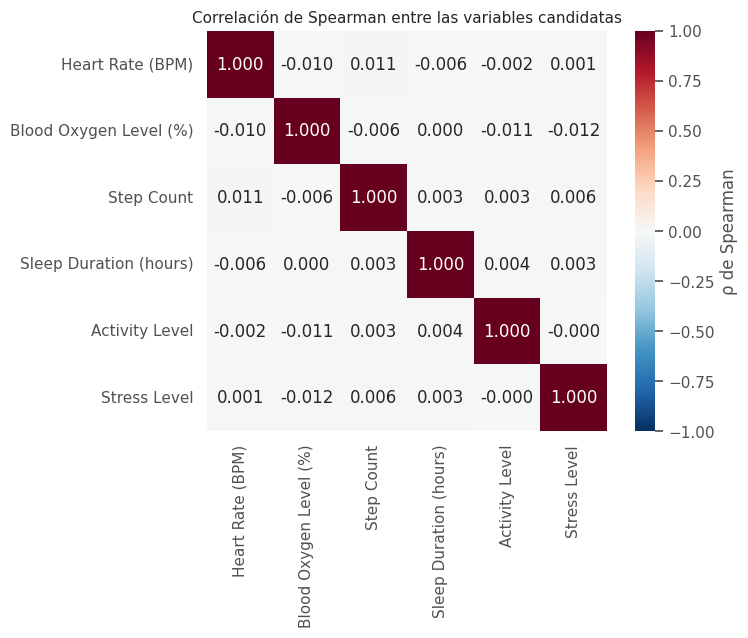

Pares con |ρ| ≥ 0.8: 0 de 15


,ρ de Spearman (5 pares más correlacionados)
Blood Oxygen Level (%) × Stress Level,-0.0123
Blood Oxygen Level (%) × Activity Level,-0.0113
Heart Rate (BPM) × Step Count,0.0107
Heart Rate (BPM) × Blood Oxygen Level (%),-0.0100
Step Count × Stress Level,0.0062


In [5]:
UMBRAL_REDUNDANCIA = 0.8

correlacion = candidatas.corr(method="spearman")
triangulo = np.triu(np.ones(correlacion.shape, dtype=bool), k=1)
pares = correlacion.where(triangulo).stack().dropna()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)
pares.index = [f"{a}  ×  {b}" for a, b in pares.index]

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlacion, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "ρ de Spearman"}, ax=ax)
ax.set_title("Correlación de Spearman entre las variables candidatas")
plt.tight_layout()
plt.show()

print(f"Pares con |ρ| ≥ {UMBRAL_REDUNDANCIA}: "
      f"{(pares.abs() >= UMBRAL_REDUNDANCIA).sum()} de {len(pares)}")
pares.head(5).to_frame("ρ de Spearman (5 pares más correlacionados)")

**Lectura.** Ningún par se acerca al umbral: la correlación absoluta más alta es 0,012
(`Blood Oxygen Level (%)` con `Stress Level`), prácticamente cero. No hay información duplicada
y no se descarta ninguna variable por redundancia, lo que confirma el resultado de la EP1, esta
vez incluyendo `Activity Level` codificada.

Este resultado tiene una segunda lectura, relevante para el resto del informe: si las
variables no se relacionan entre sí, ninguna combinación de valores debería repetirse más de
lo que indica el azar, y eso es justamente lo que un agrupamiento intenta encontrar. Los
apartados siguientes ponen a prueba esa expectativa.

### Variables conservadas y descartadas

| Variable | Filtro 1: rol | Filtro 2: varianza en `[0, 1]` | Filtro 3: \|ρ\| máximo con otra variable | Decisión |
| --- | --- | --- | --- | --- |
| `User ID` | Identificador nominal | — | — | **Descartada** |
| `Heart Rate (BPM)` | Medición biométrica | 0,024 | 0,011 | Conservada |
| `Blood Oxygen Level (%)` | Medición biométrica | 0,034 | 0,012 | Conservada |
| `Step Count` | Medición biométrica | 0,012 | 0,011 | Conservada |
| `Sleep Duration (hours)` | Medición biométrica | 0,016 | < 0,007 | Conservada |
| `Activity Level` | Nivel ordinal | 0,168 | 0,011 | Conservada |
| `Stress Level` | Nivel ordinal | 0,099 | 0,012 | Conservada |

Se conservan **seis variables** y se descarta **una** (`User ID`). La decisión coincide con la
de la EP1, pero ahora se sostiene en criterios propios del aprendizaje no supervisado: ninguna
de las seis variables conservadas es casi constante ni repite la información de otra, de modo
que todas aportan una dimensión propia al cálculo de distancias.

### Preparación de las variables para el cálculo de distancias

Los tres algoritmos de agrupamiento y las dos técnicas de reducción operan sobre distancias
euclidianas, de modo que la escala de cada variable define cuánto pesa en el resultado. Se
hacen dos ajustes respecto del preprocesamiento de la EP1:

| Ajuste | EP1 | EP5 | Motivo |
| --- | --- | --- | --- |
| Escala de las ordinales | Min-Max `[0, 1]` | Z-score, igual que las continuas | Con Min-Max, `Activity Level` y `Stress Level` quedan con desviaciones estándar de ≈ 0,41 y ≈ 0,32, frente a 1 de las continuas: en la distancia euclidiana (que suma diferencias al cuadrado) pesarían entre 6 y 10 veces menos. Con Z-score las seis variables pesan lo mismo |
| Asimetría de `Step Count` | Sin transformar | Transformación de Yeo-Johnson antes del Z-score | Su cola derecha (máximo de 62.487 pasos, ≈ 8 desviaciones sobre la media) dominaría la distancia de los registros extremos, y K-Means y el enlace completo tienden a dedicarles un grupo propio. Yeo-Johnson acerca la distribución a una simétrica sin eliminar registros y conserva el orden de los valores |

Los extremos plausibles que la EP1 decidió retener se mantienen: la transformación cambia la
escala en que se miden las distancias, no los datos.

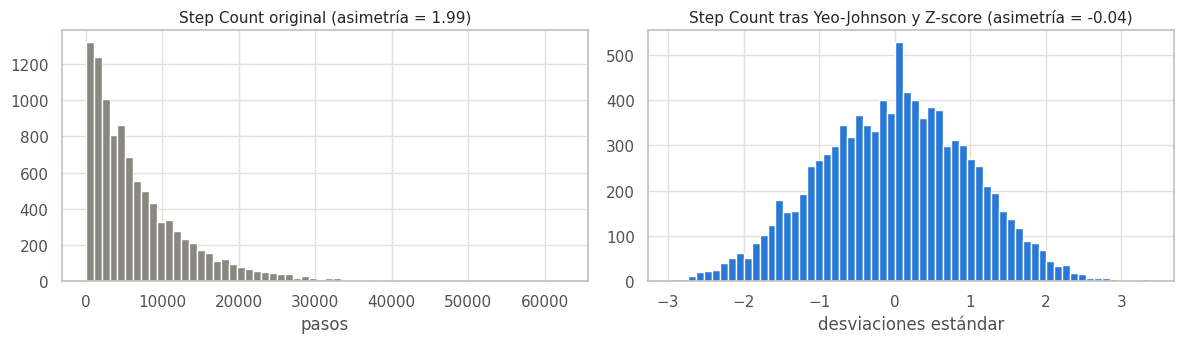

λ de Yeo-Johnson para Step Count: 0.273


,asimetría original,asimetría transformada,media,desv. estándar,mínimo,máximo
Heart Rate (BPM),0.1352,0.1352,-0.0000,1.0000,-2.5104,3.9012
Blood Oxygen Level (%),-0.5890,-0.5890,0.0000,1.0000,-4.1337,1.2616
Step Count,1.9880,-0.0382,-0.0000,1.0000,-2.9484,3.3791
Sleep Duration (hours),0.0146,0.0146,-0.0000,1.0000,-4.0023,3.8116
Activity Level,0.0611,0.0611,0.0000,1.0000,-1.1791,1.2599
Stress Level,0.0276,0.0276,0.0000,1.0000,-1.5698,1.6033


In [6]:
VARIABLES = CONTINUAS + ORDINALES

datos_modelo = candidatas[VARIABLES].copy()
asimetria_original = datos_modelo.skew()

transformador_pasos = PowerTransformer(method="yeo-johnson", standardize=False)
datos_modelo["Step Count"] = transformador_pasos.fit_transform(datos_modelo[["Step Count"]]).ravel()

escalador = StandardScaler()
X = pd.DataFrame(escalador.fit_transform(datos_modelo), columns=VARIABLES, index=datos_modelo.index)
X_valores = X.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(candidatas["Step Count"], bins=60, color=COLORES["Referencia"])
axes[0].set_title(f"Step Count original (asimetría = {asimetria_original['Step Count']:.2f})")
axes[0].set_xlabel("pasos")
axes[1].hist(X["Step Count"], bins=60, color=COLORES["K-Means"])
axes[1].set_title(f"Step Count tras Yeo-Johnson y Z-score (asimetría = {X['Step Count'].skew():.2f})")
axes[1].set_xlabel("desviaciones estándar")
plt.tight_layout()
plt.show()

print(f"λ de Yeo-Johnson para Step Count: {transformador_pasos.lambdas_[0]:.3f}")
pd.DataFrame({
    "asimetría original": asimetria_original,
    "asimetría transformada": X.skew(),
    "media": X.mean(),
    "desv. estándar": X.std(ddof=0),
    "mínimo": X.min(),
    "máximo": X.max(),
})

---

## 3. Reducción de dimensionalidad

Se aplican dos técnicas con supuestos distintos:

| Técnica | Tipo | Qué conserva | Uso en este informe |
| --- | --- | --- | --- |
| PCA | Lineal | La varianza global: busca las direcciones (combinaciones lineales de las variables) en que los datos varían más | Medir cuánta información redundante hay y si el conjunto se puede comprimir |
| t-SNE | No lineal | Las vecindades locales: los registros cercanos en las seis dimensiones quedan cercanos en el plano | Visualizar grupos que ninguna proyección lineal mostraría |

### 3.1 PCA

Si varias variables compartieran información, las primeras componentes concentrarían la
mayor parte de la varianza. Para decidir qué es "mucha" varianza se usa el **análisis
paralelo de Horn**: el PCA se repite sobre 20 versiones del conjunto en que cada columna se
permuta por separado, lo que conserva la distribución de cada variable pero destruye
cualquier relación entre ellas. Una componente solo representa estructura real si explica
más varianza que el percentil 95 de esas réplicas.

In [7]:
def permutar_columnas(datos, generador):
    """Permuta cada columna por separado: conserva cada distribución y destruye las relaciones."""
    return np.column_stack([generador.permutation(datos[:, j]) for j in range(datos.shape[1])])


pca = PCA(random_state=SEMILLA).fit(X_valores)
COMPONENTES = [f"PC{i}" for i in range(1, len(VARIABLES) + 1)]

N_REPLICAS_PCA = 20
generador = np.random.default_rng(SEMILLA)
varianza_nula = np.array([
    PCA().fit(permutar_columnas(X_valores, generador)).explained_variance_ratio_
    for _ in range(N_REPLICAS_PCA)
])
percentil_95_nulo = np.percentile(varianza_nula, 95, axis=0)
supera = pca.explained_variance_ratio_ > percentil_95_nulo

tabla_pca = pd.DataFrame({
    "varianza explicada": pca.explained_variance_ratio_,
    "varianza acumulada": np.cumsum(pca.explained_variance_ratio_),
    "percentil 95 sin estructura": percentil_95_nulo,
    "supera la referencia": supera,
    # Regla de Horn: se retienen componentes en orden mientras superen su referencia.
    "retenida (análisis paralelo)": np.logical_and.accumulate(supera),
}, index=COMPONENTES)
print(f"Componentes retenidas por el análisis paralelo: {int(tabla_pca['retenida (análisis paralelo)'].sum())}")

for meta in (0.80, 0.90):
    n = int(np.searchsorted(tabla_pca["varianza acumulada"].to_numpy(), meta) + 1)
    print(f"Componentes necesarias para explicar el {meta:.0%} de la varianza: "
          f"{n} de {len(VARIABLES)}")
print(f"Referencia con variables independientes: 1/{len(VARIABLES)} = "
      f"{1 / len(VARIABLES):.3f} de la varianza por componente")

tabla_pca

Componentes retenidas por el análisis paralelo: 0
Componentes necesarias para explicar el 80% de la varianza: 5 de 6
Componentes necesarias para explicar el 90% de la varianza: 6 de 6
Referencia con variables independientes: 1/6 = 0.167 de la varianza por componente


,varianza explicada,varianza acumulada,percentil 95 sin estructura,supera la referencia,retenida (análisis paralelo)
PC1,0.1698,0.1698,0.1732,False,False
PC2,0.1681,0.3379,0.1709,False,False
PC3,0.1675,0.5054,0.1685,False,False
PC4,0.1658,0.6712,0.1665,False,False
PC5,0.1648,0.8360,0.1655,False,False
PC6,0.1640,1.0000,0.1638,True,False


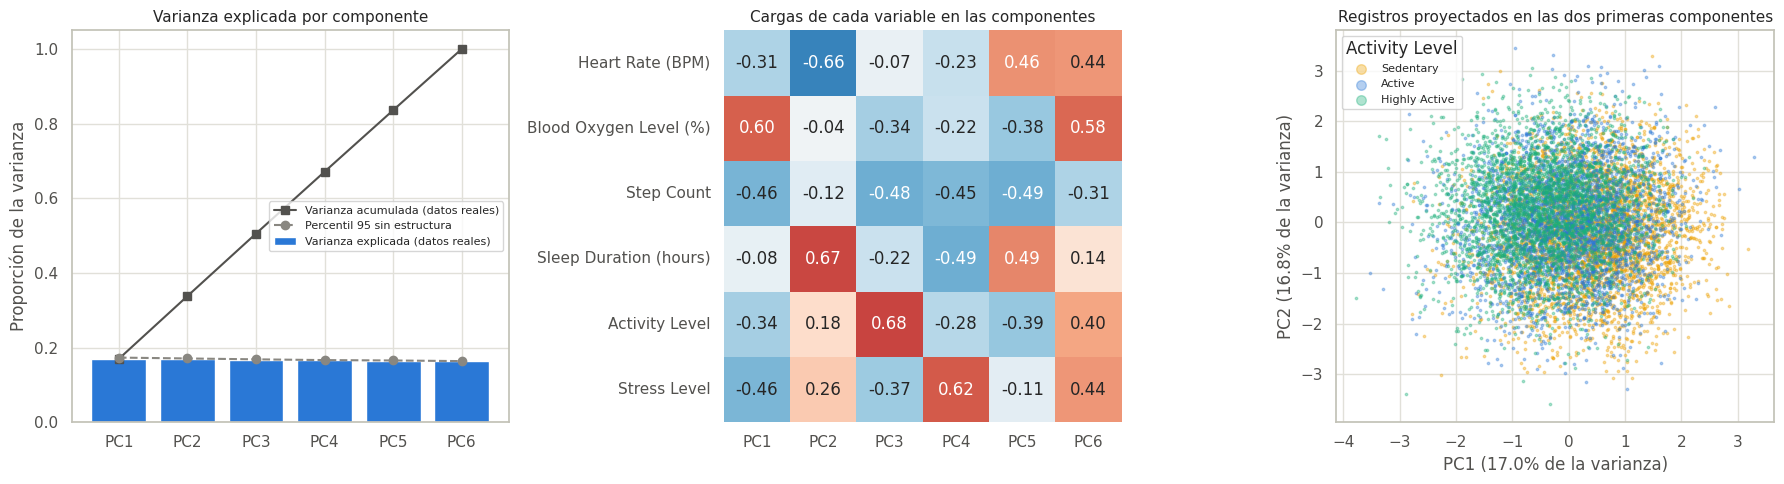

In [8]:
proyeccion_pca = pca.transform(X_valores)
actividad = limpio["Activity Level"].to_numpy()
cargas = pd.DataFrame(pca.components_.T, index=VARIABLES, columns=COMPONENTES)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1.1, 1, 1.1]})

ax = axes[0]
posiciones = np.arange(len(COMPONENTES))
ax.bar(posiciones, tabla_pca["varianza explicada"], color=COLORES["K-Means"],
       label="Varianza explicada (datos reales)")
ax.plot(posiciones, tabla_pca["varianza acumulada"], "s-", color="#52514e",
        label="Varianza acumulada (datos reales)")
ax.plot(posiciones, percentil_95_nulo, "o--", color=COLORES["Referencia"],
        label="Percentil 95 sin estructura")
ax.set_xticks(posiciones, COMPONENTES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Proporción de la varianza")
ax.set_title("Varianza explicada por componente")
ax.legend(fontsize=8, loc="center right")

ax = axes[1]
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Cargas de cada variable en las componentes")

ax = axes[2]
for nivel in ORDEN_ACTIVIDAD:
    m = actividad == nivel
    ax.scatter(proyeccion_pca[m, 0], proyeccion_pca[m, 1], s=3, alpha=0.35,
               color=COLORES_ACTIVIDAD[nivel], label=nivel)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} de la varianza)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} de la varianza)")
ax.set_title("Registros proyectados en las dos primeras componentes")
ax.legend(title="Activity Level", markerscale=4, fontsize=8)

plt.tight_layout()
plt.show()

**Lectura del resultado.**

- Las seis componentes explican casi la misma proporción de la varianza, entre 16,4 % y 17,0 %,
  muy cerca del 16,7 % (1/6) que corresponde a seis variables independientes. La varianza
  acumulada crece en línea recta: se necesitan 5 componentes para llegar al 80 % y las 6 para
  el 90 %. **El PCA no logra comprimir el conjunto**: reducirlo a dos o tres componentes
  descartaría entre la mitad y dos tercios de la información.
- El análisis paralelo lo confirma. La primera componente (17,0 %) no supera el percentil 95 de
  las réplicas sin estructura (17,3 %), por lo que no se retiene ninguna componente. La sexta
  queda por encima de su referencia solo porque, en datos sin estructura, la última componente
  es la más pequeña por azar; superarla indica que las varianzas reales están todavía más
  parejas, no que exista estructura.
- Las cargas no muestran un patrón interpretable. Cada componente combina variables sin
  relación fisiológica entre sí (por ejemplo, PC2 opone pulso y duración del sueño, y PC3 está
  dominada por `Activity Level`). Además, cuando todas las componentes explican lo mismo, la
  orientación de cada una es arbitraria: otra muestra produciría cargas distintas.
- En la proyección PC1–PC2 los registros forman una sola nube elíptica, sin separaciones, y los
  tres niveles de actividad se superponen.

### 3.2 t-SNE

t-SNE (*t-distributed Stochastic Neighbor Embedding*) convierte las distancias entre
registros en probabilidades de ser vecinos y busca una disposición en el plano que conserve
esas vecindades. Su hiperparámetro principal es la **perplejidad**, que equivale al número
efectivo de vecinos que considera cada registro. Tiene dos limitaciones que condicionan su
lectura:

- En el mapa resultante, el tamaño de los grupos y la distancia entre ellos no tienen
  significado; solo lo tiene qué registros quedan juntos.
- Con perplejidades bajas puede fragmentar una nube homogénea en grupos aparentes.

Por eso primero se comparan tres perplejidades sobre una muestra de 3.000 registros, y luego
se proyecta el conjunto completo con el valor intermedio (30, el valor por defecto).

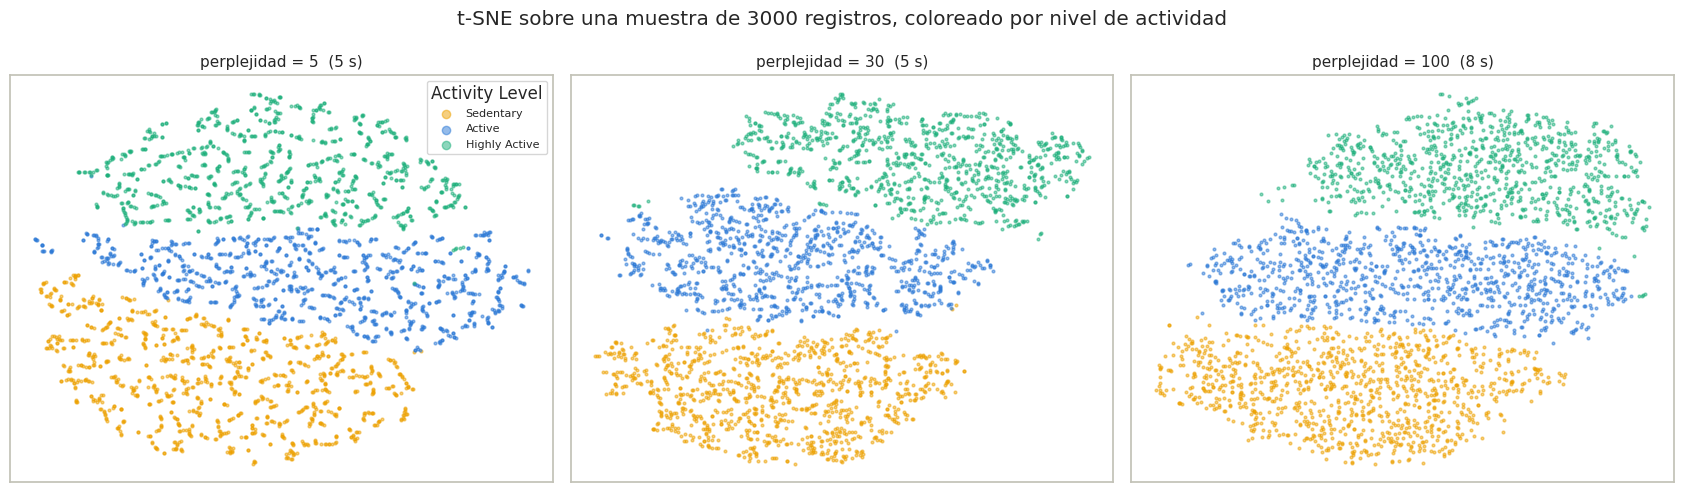

In [9]:
MUESTRA_TSNE = 3000
PERPLEJIDADES = [5, 30, 100]

generador = np.random.default_rng(SEMILLA)
indices_muestra = generador.choice(len(X_valores), size=MUESTRA_TSNE, replace=False)

fig, axes = plt.subplots(1, len(PERPLEJIDADES), figsize=(17, 5))
for ax, perplejidad in zip(axes, PERPLEJIDADES):
    inicio = time.perf_counter()
    tsne_muestra = TSNE(n_components=2, perplexity=perplejidad, init="pca",
                        learning_rate="auto", random_state=SEMILLA)
    proyeccion = tsne_muestra.fit_transform(X_valores[indices_muestra])
    for nivel in ORDEN_ACTIVIDAD:
        m = actividad[indices_muestra] == nivel
        ax.scatter(proyeccion[m, 0], proyeccion[m, 1], s=4, alpha=0.5,
                   color=COLORES_ACTIVIDAD[nivel], label=nivel)
    ax.set_title(f"perplejidad = {perplejidad}  ({time.perf_counter() - inicio:.0f} s)")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].legend(title="Activity Level", markerscale=3, fontsize=8)
fig.suptitle(f"t-SNE sobre una muestra de {MUESTRA_TSNE} registros, coloreado por nivel de actividad")
plt.tight_layout()
plt.show()

t-SNE sobre 10000 registros: 20 s | divergencia KL final = 2.040


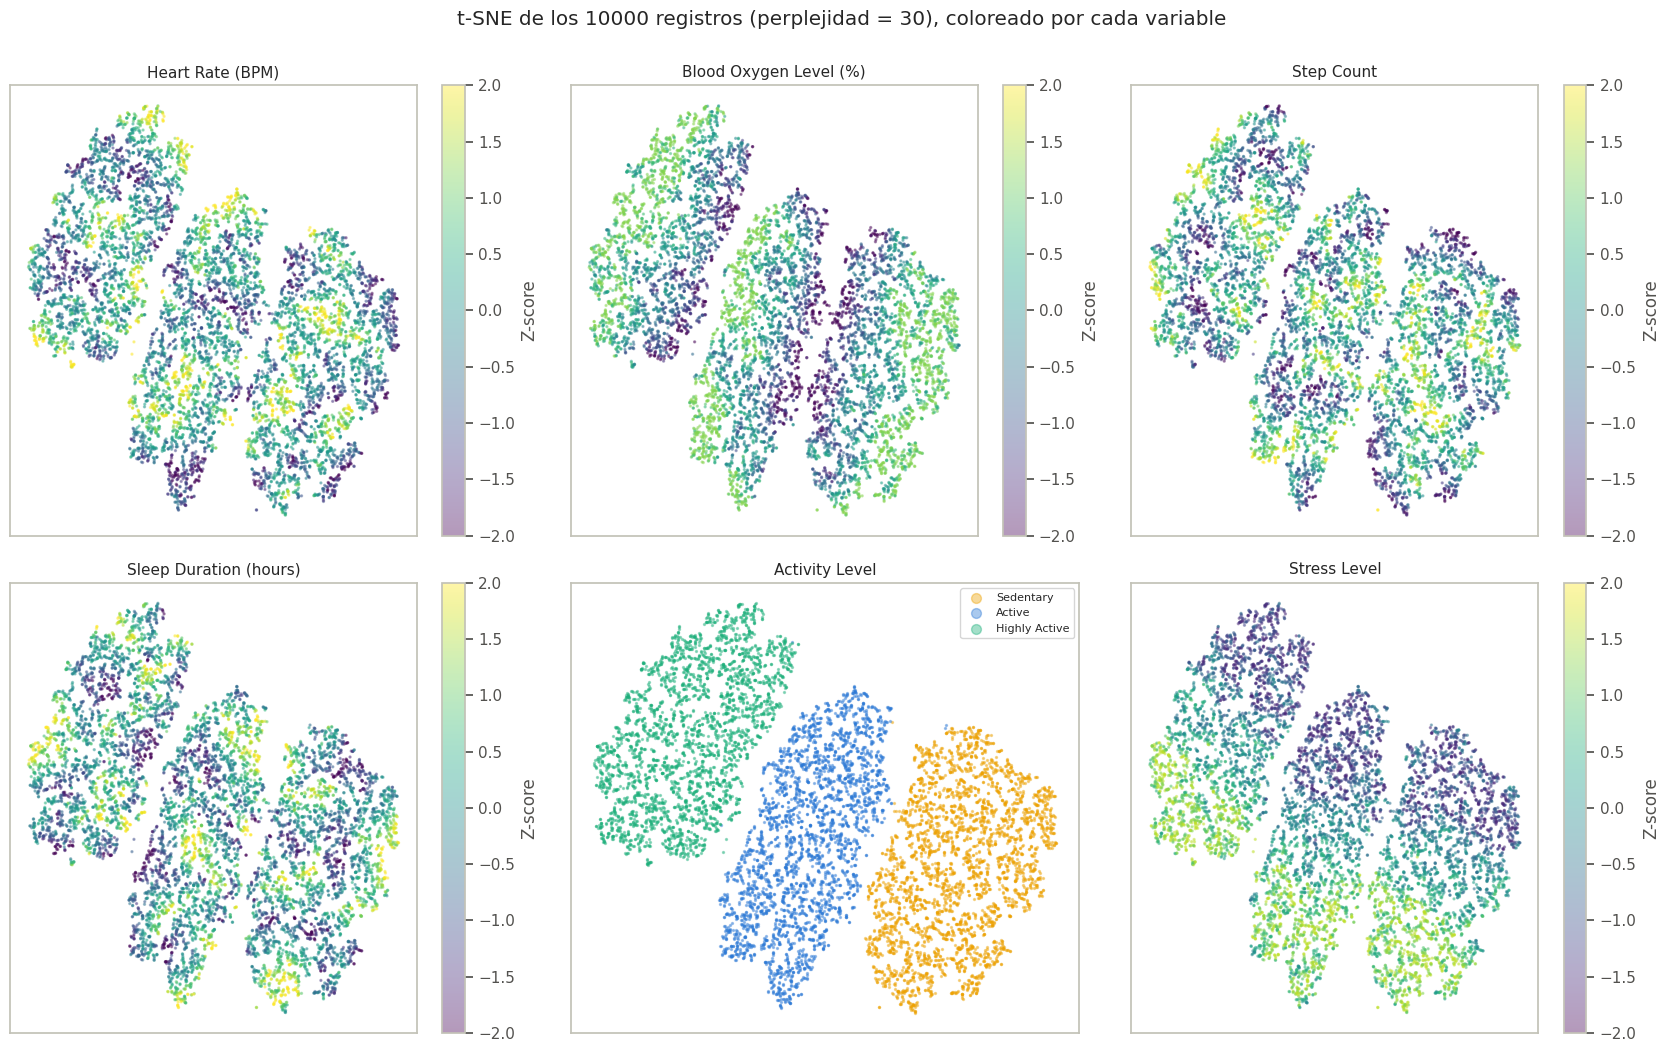

In [10]:
PERPLEJIDAD = 30

inicio = time.perf_counter()
tsne = TSNE(n_components=2, perplexity=PERPLEJIDAD, init="pca", learning_rate="auto",
            random_state=SEMILLA)
proyeccion_tsne = tsne.fit_transform(X_valores)
print(f"t-SNE sobre {len(X_valores)} registros: {time.perf_counter() - inicio:.0f} s | "
      f"divergencia KL final = {tsne.kl_divergence_:.3f}")

fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
for ax, variable in zip(axes.flat, VARIABLES):
    if variable == "Activity Level":
        for nivel in ORDEN_ACTIVIDAD:
            m = actividad == nivel
            ax.scatter(proyeccion_tsne[m, 0], proyeccion_tsne[m, 1], s=2, alpha=0.4,
                       color=COLORES_ACTIVIDAD[nivel], label=nivel)
        ax.legend(markerscale=5, fontsize=8, loc="upper right")
    else:
        puntos = ax.scatter(proyeccion_tsne[:, 0], proyeccion_tsne[:, 1], s=2, alpha=0.4,
                            c=X[variable], cmap="viridis", vmin=-2, vmax=2)
        fig.colorbar(puntos, ax=ax, label="Z-score")
    ax.set_title(variable)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"t-SNE de los {len(X_valores)} registros (perplejidad = {PERPLEJIDAD}), "
             "coloreado por cada variable", y=1.0)
plt.tight_layout()
plt.show()

**Lectura del resultado.**

- A diferencia del PCA, t-SNE sí muestra grupos: **tres islas claramente separadas**, que se
  mantienen con las tres perplejidades probadas y en el conjunto completo.
- El coloreado por variable muestra que esas islas corresponden **exactamente a los tres niveles
  de `Activity Level`**. Ninguna otra variable se organiza por isla: pulso, oxigenación, pasos y
  sueño aparecen mezclados dentro de cada una, y `Stress Level` solo forma franjas internas por
  sus diez niveles discretos.
- La explicación es geométrica y no biométrica. Tras el Z-score, `Activity Level` toma solo tres
  valores (−1,18, 0,04 y 1,26), separados por ≈ 1,2 desviaciones estándar. Dos registros con
  distinto nivel de actividad están siempre al menos a esa distancia, mientras que los vecinos
  más cercanos de la mayoría de los registros están a menos de 0,87 (mediana de la distancia al
  vecino n.° 11, apartado 4.3). t-SNE, que solo conserva vecindades, separa entonces los tres
  "planos" de actividad y los dibuja como islas.
- t-SNE, por lo tanto, no revela perfiles de usuario: revela que una de las seis variables es
  discreta, con tres valores. Es la limitación anunciada al presentar la técnica: que el mapa
  muestre islas no implica que existan grupos con significado.

### 3.3 Síntesis de la reducción de dimensionalidad

| Pregunta | PCA | t-SNE |
| --- | --- | --- |
| ¿Comprime el conjunto? | No: las seis componentes explican lo mismo (≈ 16,7 % cada una) | No aplica: es una técnica de visualización |
| ¿Muestra grupos? | No: una sola nube | Sí: tres islas, que coinciden con los tres niveles de `Activity Level` |
| Lectura | No hay redundancia ni direcciones dominantes | La única separación proviene de que una variable es discreta |

**Decisión para el agrupamiento.** Los algoritmos del apartado 4 se ajustan sobre las **seis
variables estandarizadas** y no sobre proyecciones:

- Reducir con PCA no aporta: para conservar el 90 % de la varianza se necesitan las seis
  componentes, es decir, el mismo espacio original rotado.
- t-SNE no conserva distancias ni densidades globales, de modo que agrupar sobre su proyección
  produciría las tres islas por construcción. Se usa solo para visualizar los resultados.

La reducción de dimensionalidad deja una hipótesis concreta para el apartado 4: si los
algoritmos encuentran grupos, lo más probable es que reproduzcan los niveles de
`Activity Level`.

---

## 4. Modelamiento de agrupamiento

Se aplican tres algoritmos que definen "grupo" de forma distinta, para que la conclusión no
dependa de los supuestos de uno solo:

| Algoritmo | Qué entiende por grupo | Hiperparámetros explorados |
| --- | --- | --- |
| K-Means | Registros cercanos a un mismo centroide; supone grupos compactos, convexos y de tamaño similar | Número de grupos `k` (2 a 10), inicialización (`k-means++` o aleatoria) y número de reinicios `n_init` |
| Jerárquico aglomerativo | Registros que se unen de abajo hacia arriba según un criterio de enlace, hasta formar un árbol que se corta en `k` grupos | Enlace (`ward`, `complete` y `average`) y número de grupos `k` (2 a 10) |
| DBSCAN | Regiones densas separadas por zonas poco densas; los registros aislados se marcan como ruido y no se asignan a ningún grupo | Radio de vecindad `eps` y número mínimo de vecinos `min_samples` |

Los tres se ajustan sobre las seis variables estandarizadas del apartado 2, por las razones
expuestas en la síntesis del apartado 3.

**Regla común de selección.** En cada algoritmo se elige la configuración con mayor
**coeficiente de Silhouette** (definido en el apartado 6), con dos restricciones que evitan
soluciones triviales:

- El grupo más pequeño debe reunir al menos el **5 %** de los registros. Un "grupo" de diez
  registros extremos puede elevar el Silhouette sin describir a ningún segmento de usuarios.
- En DBSCAN, el ruido no puede superar el **10 %** de los registros. De lo contrario, el
  algoritmo mejora sus índices descartando los registros difíciles de asignar.

Los índices de Calinski-Harabasz y Davies-Bouldin se registran en todas las configuraciones
como apoyo a la decisión.

In [11]:
TAMANO_MINIMO = 5.0   # % de registros que debe reunir el grupo más pequeño
RUIDO_MAXIMO = 10.0   # % máximo de registros marcados como ruido (DBSCAN)
INDICES = ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]


def indices_validacion(datos, etiquetas):
    """Índices internos de un agrupamiento; los registros de ruido (-1) se excluyen del cálculo."""
    etiquetas = np.asarray(etiquetas)
    validos = etiquetas != -1
    tamanos = pd.Series(etiquetas[validos]).value_counts()
    fila = {
        "grupos": len(tamanos),
        "% grupo menor": tamanos.min() / len(etiquetas) * 100 if len(tamanos) else np.nan,
        "% ruido": (~validos).mean() * 100,
        **{indice: np.nan for indice in INDICES},
    }
    if len(tamanos) >= 2:
        fila["Silhouette"] = silhouette_score(datos[validos], etiquetas[validos])
        fila["Calinski-Harabasz"] = calinski_harabasz_score(datos[validos], etiquetas[validos])
        fila["Davies-Bouldin"] = davies_bouldin_score(datos[validos], etiquetas[validos])
    return fila


def seleccionar(tabla):
    """Configuración de mayor Silhouette entre las que cumplen el tamaño mínimo y el ruido máximo."""
    admisibles = tabla[(tabla["grupos"] >= 2) & (tabla["% grupo menor"] >= TAMANO_MINIMO)
                       & (tabla["% ruido"] <= RUIDO_MAXIMO)]
    if admisibles.empty:
        print("Ninguna configuración cumple las restricciones: se elige la de mayor Silhouette "
              "entre las que forman al menos dos grupos.")
        admisibles = tabla[tabla["grupos"] >= 2]
    if admisibles.empty:
        print("Ninguna configuración forma dos grupos: se elige la de menor ruido.")
        return tabla["% ruido"].idxmin()
    return admisibles["Silhouette"].idxmax()


def tamanos_grupos(etiquetas):
    """Texto con el número de registros de cada grupo (y del ruido, si existe)."""
    conteo = pd.Series(etiquetas).value_counts().sort_index()
    return ", ".join(("ruido" if g == -1 else f"G{g}") + f": {n}" for g, n in conteo.items())

### 4.1 K-Means

K-Means asigna cada registro al centroide más cercano y recalcula los centroides hasta que
las asignaciones dejan de cambiar, minimizando la **inercia** (suma de distancias al
cuadrado de cada registro a su centroide). La inercia siempre disminuye al aumentar `k`, por
lo que no sirve por sí sola para elegirlo: se usa para el método del codo, junto con los tres
índices de validación interna.

In [12]:
K_RANGO = range(2, 11)

filas, etiquetas_km = [], {}
for k in K_RANGO:
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEMILLA).fit(X_valores)
    etiquetas_km[k] = modelo.labels_
    filas.append({"k": k, "inercia": modelo.inertia_, **indices_validacion(X_valores, modelo.labels_)})

tabla_km = pd.DataFrame(filas).set_index("k")
k_km = seleccionar(tabla_km)
print(f"K-Means seleccionado: k = {k_km}")

tabla_km

K-Means seleccionado: k = 2


,inercia,grupos,% grupo menor,% ruido,Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,,,,,
2,52487.0315,2,46.9000,0.0000,0.1285,1431.1676,2.5431
3,47497.2713,3,32.0200,0.0000,0.1214,1315.7575,2.2933
4,43803.5513,4,20.4500,0.0000,0.1200,1232.0244,2.0419
5,41028.5559,5,17.3800,0.0000,0.1196,1155.4230,1.9185
6,38729.7811,6,14.9500,0.0000,0.1201,1097.7423,1.7728
7,36711.7468,7,12.9400,0.0000,0.1198,1056.5218,1.6966
8,35220.9507,8,10.9000,0.0000,0.1174,1004.2603,1.6475
9,33856.8480,9,9.7400,0.0000,0.1183,964.3444,1.6165
10,32700.5470,10,8.5200,0.0000,0.1207,926.6666,1.5838


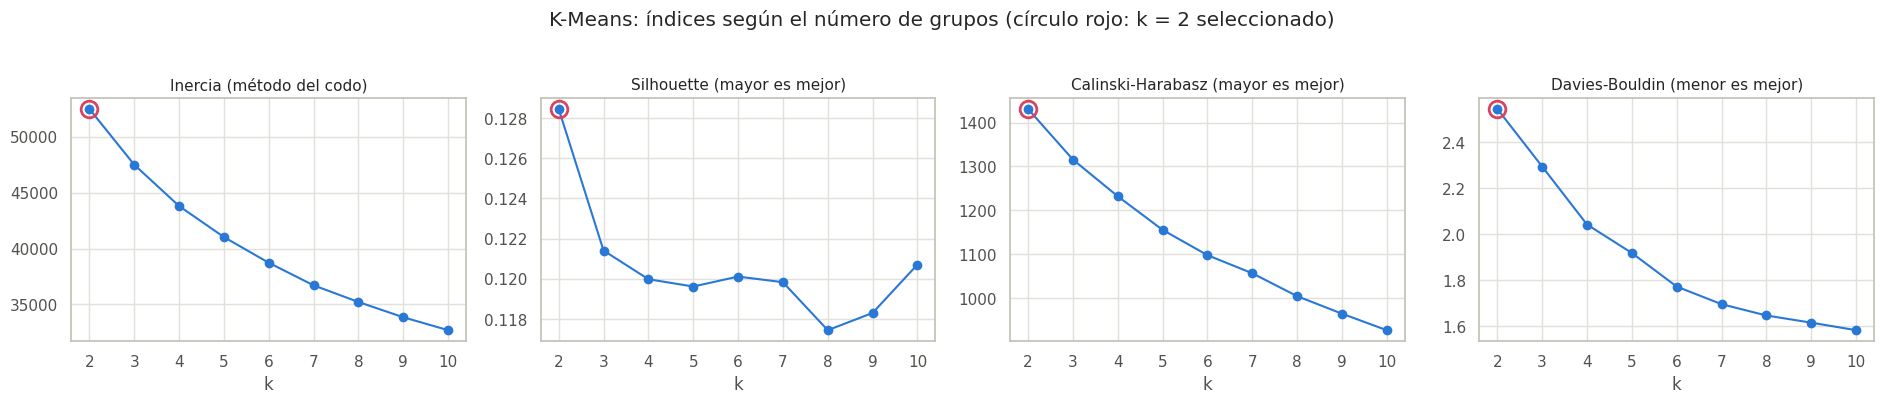

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.9))
paneles = [("inercia", "Inercia (método del codo)"), ("Silhouette", "Silhouette (mayor es mejor)"),
           ("Calinski-Harabasz", "Calinski-Harabasz (mayor es mejor)"),
           ("Davies-Bouldin", "Davies-Bouldin (menor es mejor)")]
for ax, (columna, titulo) in zip(axes, paneles):
    ax.plot(tabla_km.index, tabla_km[columna], "o-", color=COLORES["K-Means"])
    ax.plot(k_km, tabla_km.loc[k_km, columna], "o", **MARCA_SELECCION)
    ax.set_title(titulo)
    ax.set_xlabel("k")
    ax.set_xticks(list(K_RANGO))
fig.suptitle(f"K-Means: índices según el número de grupos (círculo rojo: k = {k_km} seleccionado)",
             y=1.03)
plt.tight_layout()
plt.show()

Con `k` fijo, se comprueba si la inicialización cambia la solución: `k-means++` elige
centroides iniciales alejados entre sí, mientras que `random` los elige al azar; `n_init`
indica cuántas veces se reinicia el algoritmo, conservando la solución de menor inercia. El
índice de Rand ajustado (ARI) mide la coincidencia con la configuración seleccionada: 1
indica la misma partición y 0, una coincidencia atribuible al azar.

In [14]:
filas = []
for init in ["k-means++", "random"]:
    for n_init in [1, 10]:
        modelo = KMeans(n_clusters=k_km, init=init, n_init=n_init, random_state=SEMILLA).fit(X_valores)
        filas.append({
            "init": init, "n_init": n_init, "inercia": modelo.inertia_,
            "iteraciones": modelo.n_iter_,
            "Silhouette": silhouette_score(X_valores, modelo.labels_),
            "ARI con la configuración seleccionada": adjusted_rand_score(etiquetas_km[k_km], modelo.labels_),
        })

pd.DataFrame(filas).set_index(["init", "n_init"])

inercia  iteraciones  Silhouette  \
init      n_init                                       
k-means++ 1      53130.5595           35      0.1183   
          10     52487.0315           21      0.1285   
random    1      52549.4662           26      0.1270   
          10     52473.6772           50      0.1291   

                  ARI con la configuración seleccionada  
init      n_init                                         
k-means++ 1                                      0.0874  
          10                                     1.0000  
random    1                                      0.4629  
          10                                     0.4240

**Lectura del resultado.**

- El Silhouette es bajo y casi plano en todo el rango: va de 0,117 a 0,129, con su máximo en
  **k = 2**, la configuración seleccionada (grupos de 53 % y 47 % de los registros). Ningún
  valor de k se acerca a 0,25, el límite inferior de la "estructura débil".
- La inercia disminuye de forma suave, sin un codo definido. Los índices tampoco coinciden en
  un k "natural": Silhouette y Calinski-Harabasz son máximos en k = 2, el menor valor probado,
  mientras que Davies-Bouldin mejora de forma continua hasta k = 10. Cuando hay grupos reales,
  los tres índices suelen coincidir en un mismo k, como se verá en el control positivo del
  apartado 6.3.
- La inicialización cambia la partición. Con un solo reinicio, `k-means++` llega a una inercia
  apenas 1,2 % mayor que la seleccionada, pero con una partición casi totalmente distinta
  (ARI = 0,09). Con inicialización aleatoria y 10 reinicios se obtiene incluso una inercia
  levemente menor (52.474 frente a 52.487) y un Silhouette prácticamente igual, con una partición
  que coincide solo en parte (ARI = 0,42). Se mantiene `k-means++`, la inicialización por
  defecto, porque la diferencia es despreciable. Que particiones tan distintas tengan casi la
  misma calidad es un síntoma típico de datos sin grupos: no hay un corte "correcto", sino
  muchos cortes equivalentes de una misma nube.

### 4.2 Jerárquico aglomerativo

El algoritmo parte con cada registro como un grupo y, en cada paso, une los dos grupos más
cercanos según el **criterio de enlace**:

| Enlace | Distancia entre dos grupos | Tendencia |
| --- | --- | --- |
| `ward` | Aumento de la varianza interna que produce unirlos | Grupos compactos y de tamaño parecido, similar a K-Means |
| `complete` | Distancia entre sus dos registros más alejados | Grupos de diámetro acotado; sensible a los extremos |
| `average` | Distancia promedio entre todos sus pares de registros | Intermedio; tiende a aislar registros extremos en grupos pequeños |

Se construye el árbol una sola vez por enlace con `scipy.cluster.hierarchy.linkage` y se corta
en cada valor de `k` con `fcluster`. Es el mismo algoritmo de `AgglomerativeClustering` de
scikit-learn, pero evita reconstruir el árbol completo para cada `k`.

In [15]:
METODOS_ENLACE = ["ward", "complete", "average"]

enlaces, etiquetas_jer, filas = {}, {}, []
for metodo in METODOS_ENLACE:
    inicio = time.perf_counter()
    enlaces[metodo] = linkage(X_valores, method=metodo)
    for k in K_RANGO:
        etiquetas = fcluster(enlaces[metodo], t=k, criterion="maxclust") - 1
        etiquetas_jer[(metodo, k)] = etiquetas
        filas.append({"enlace": metodo, "k": k, **indices_validacion(X_valores, etiquetas)})
    print(f"Enlace {metodo:<8}: árbol construido y evaluado en {time.perf_counter() - inicio:.0f} s")

tabla_jer = pd.DataFrame(filas).set_index(["enlace", "k"])
mejor_jer = seleccionar(tabla_jer)
print(f"\nJerárquico seleccionado: enlace = {mejor_jer[0]}, k = {mejor_jer[1]}")

tabla_jer

Enlace ward    : árbol construido y evaluado en 12 s


Enlace complete: árbol construido y evaluado en 12 s


Enlace average : árbol construido y evaluado en 13 s

Jerárquico seleccionado: enlace = ward, k = 2


grupos  % grupo menor  % ruido  Silhouette  Calinski-Harabasz  \
enlace   k                                                                   
ward     2        2        48.1700   0.0000      0.0809           840.0916   
         3        3        19.9600   0.0000      0.0731           830.5826   
         4        4        19.9600   0.0000      0.0641           800.7535   
         5        5        11.3800   0.0000      0.0574           745.3882   
         6        6        10.2000   0.0000      0.0561           709.3443   
         7        7        10.0200   0.0000      0.0535           684.7441   
         8        8         6.5700   0.0000      0.0444           651.8602   
         9        9         6.5700   0.0000      0.0394           627.3687   
         10      10         5.0800   0.0000      0.0391           610.6115   
complete 2        2        20.1900   0.0000      0.0266           442.4209   
         3        3        20.1900   0.0000      0.0307           552.4248   
         4        4        18.3500   0.0000      0.0350           595.2225   
         5        5        13.0800   0.0000      0.0269           569.2455   
         6        6         9.6300   0.0000      0.0206           509.1898   
         7        7         9.6300   0.0000      0.0232           518.0918   
         8        8         8.5300   0.0000      0.0214           503.2865   
         9        9         3.4000   0.0000      0.0175           469.8539   
         10      10         0.7400   0.0000      0.0116           431.6595   
average  2        2         0.0200   0.0000      0.3269             6.2493   
         3        3         0.0200   0.0000      0.2270             5.9770   
         4        4         0.0200   0.0000      0.1597             9.6556   
         5        5         0.0200   0.0000      0.1025            21.2180   
         6        6         0.0200   0.0000      0.0608            44.5108   
         7        7         0.0200   0.0000      0.0235            53.9833   
         8        8         0.0200   0.0000      0.0004            52.3249   
         9        9         0.0200   0.0000     -0.0110            47.0965   
         10      10         0.0200   0.0000     -0.0262            43.7956   

             Davies-Bouldin  
enlace   k                   
ward     2           3.3317  
         3           2.7157  
         4           2.6327  
         5           2.4394  
         6           2.3355  
         7           2.1875  
         8           2.1414  
         9           2.1252  
         10          2.0826  
complete 2           3.5256  
         3           3.4928  
         4           2.8743  
         5           2.7492  
         6           2.9209  
         7           2.8258  
         8           2.6395  
         9           2.6075  
         10          2.5500  
average  2           0.8817  
         3           0.9129  
         4           1.0243  
         5           1.1910  
         6           1.4161  
         7           1.4469  
         8           1.3859  
         9           1.3378  
         10          1.3083

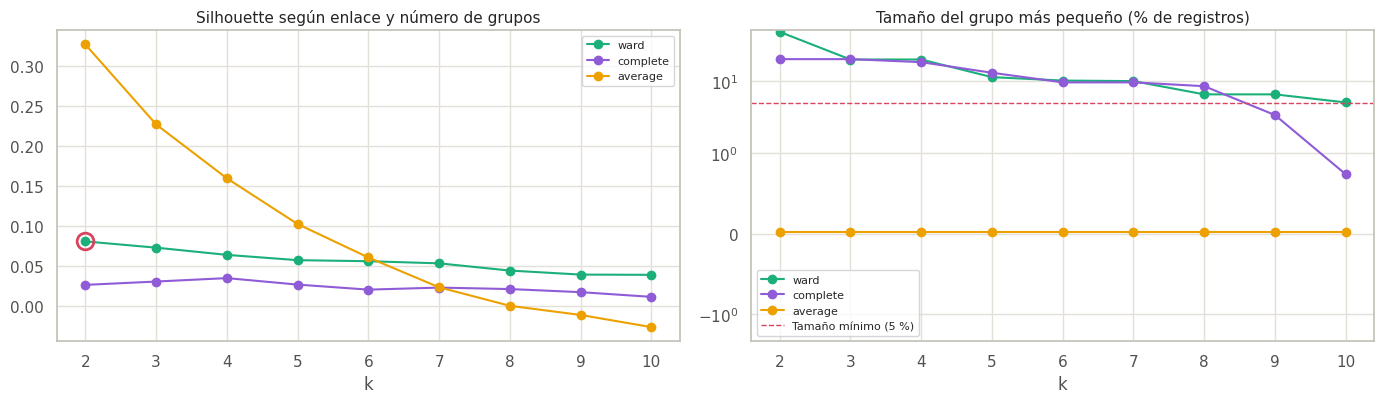

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for metodo in METODOS_ENLACE:
    datos_enlace = tabla_jer.loc[metodo]
    axes[0].plot(datos_enlace.index, datos_enlace["Silhouette"], "o-",
                 color=COLORES_ENLACE[metodo], label=metodo)
    axes[1].plot(datos_enlace.index, datos_enlace["% grupo menor"], "o-",
                 color=COLORES_ENLACE[metodo], label=metodo)
axes[0].plot(mejor_jer[1], tabla_jer.loc[mejor_jer, "Silhouette"], "o", **MARCA_SELECCION)
axes[0].set_title("Silhouette según enlace y número de grupos")
axes[1].axhline(TAMANO_MINIMO, color="#d6455d", ls="--", lw=1,
                label=f"Tamaño mínimo ({TAMANO_MINIMO:.0f} %)")
axes[1].set_title("Tamaño del grupo más pequeño (% de registros)")
axes[1].set_yscale("symlog", linthresh=1)
for ax in axes:
    ax.set_xlabel("k")
    ax.set_xticks(list(K_RANGO))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

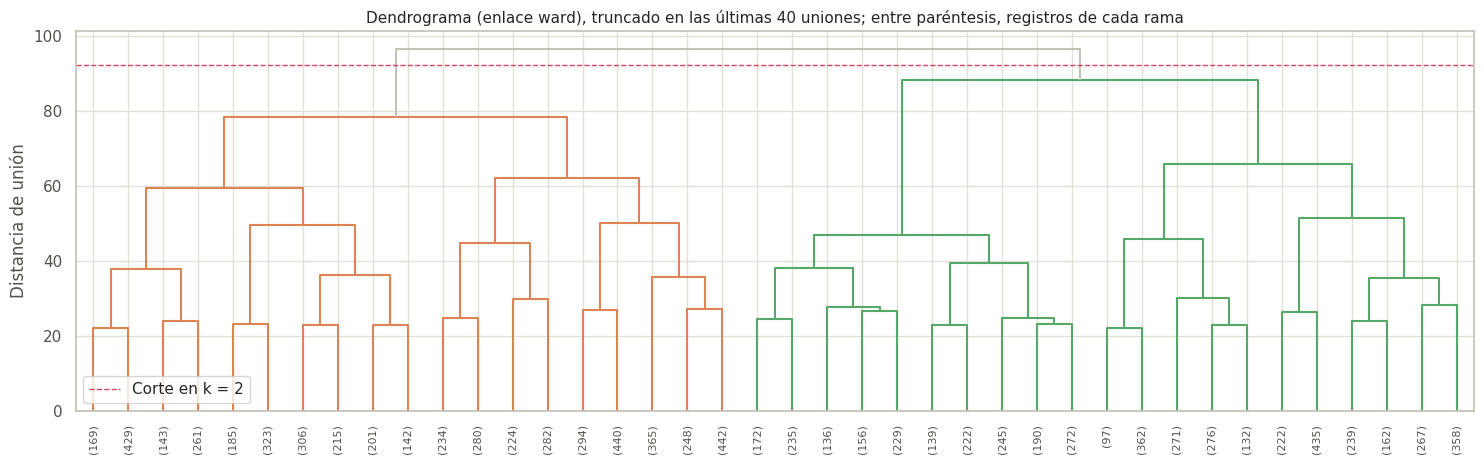

In [17]:
metodo, k = mejor_jer
arbol = enlaces[metodo]
# El corte que deja k grupos queda entre la unión que pasa de k + 1 a k grupos y la que pasa de k a k - 1.
altura_corte = (arbol[-k, 2] + arbol[-(k - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(15, 4.8))
dendrogram(arbol, truncate_mode="lastp", p=40, color_threshold=altura_corte,
           above_threshold_color="#c3c2b7", show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=8, ax=ax)
ax.axhline(altura_corte, color="#d6455d", ls="--", lw=1, label=f"Corte en k = {k}")
ax.set_title(f"Dendrograma (enlace {metodo}), truncado en las últimas 40 uniones; "
             "entre paréntesis, registros de cada rama")
ax.set_ylabel("Distancia de unión")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura del resultado.**

- `ward` obtiene los Silhouette más altos entre las configuraciones admisibles, aunque menores
  que los de K-Means: 0,081 con k = 2 (seleccionado), bajando hasta 0,039 con k = 10. `complete`
  queda entre 0,012 y 0,035.
- `average` ilustra por qué se exige un tamaño mínimo de grupo. Con k = 2 alcanza el Silhouette
  más alto de todo el apartado (0,327), pero su grupo menor reúne solo el 0,02 % de los
  registros (2 registros). No encontró dos segmentos, sino una nube completa más dos registros
  extremos, que quedan lejos de todo el resto y por eso tienen silueta alta. Su
  Calinski-Harabasz (6,2) delata la situación. Sin la restricción, esta configuración habría
  sido la seleccionada.
- En el dendrograma de `ward` las uniones ocurren a alturas que crecen de forma gradual. No hay
  un salto marcado que indique dónde cortar, que es lo que se observaría si existieran grupos
  separados. El corte en k = 2 divide los datos en dos mitades de tamaño parecido (5.183 y 4.817
  registros), cuya unión ocurre a una altura solo algo mayor que la unión anterior.

### 4.3 DBSCAN

DBSCAN considera **núcleo** a todo registro que tiene al menos `min_samples` registros
(incluido él mismo) a una distancia menor que `eps`. Los núcleos conectados forman un grupo,
los registros cercanos a un núcleo se suman a su grupo y el resto se marca como ruido (`-1`).
No requiere fijar el número de grupos: lo determina la densidad de los datos.

Para elegir `eps` se usa el **gráfico de distancia al k-ésimo vecino**: con
`min_samples = 2 × número de variables = 12` (regla habitual de Sander *et al.*, 1998), se
ordena la distancia de cada registro a su vecino número 11 (el duodécimo punto contando al
propio registro). Si hubiera grupos densos separados por zonas vacías, la curva mostraría un
codo marcado. La grilla de `eps` se construye con percentiles de esa distancia, y se combina
con tres valores de `min_samples` (6, 12 y 24).

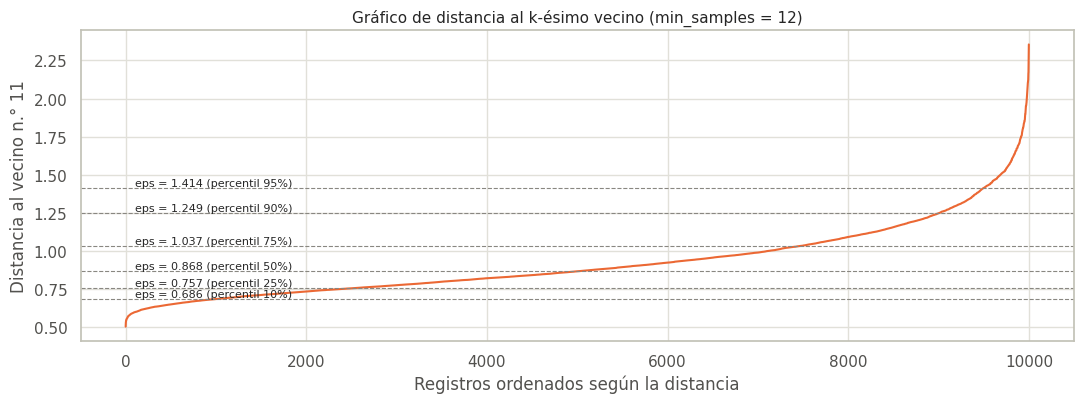

Grilla de eps: [0.686, 0.757, 0.868, 1.037, 1.249, 1.414]


In [18]:
MIN_SAMPLES_REFERENCIA = 2 * X_valores.shape[1]

vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES_REFERENCIA).fit(X_valores)
distancias, _ = vecinos.kneighbors(X_valores)
distancia_k = np.sort(distancias[:, -1])

PERCENTILES_EPS = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
EPS_GRILLA = np.round(np.quantile(distancia_k, PERCENTILES_EPS), 3)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(distancia_k, color=COLORES["DBSCAN"])
for percentil, eps in zip(PERCENTILES_EPS, EPS_GRILLA):
    ax.axhline(eps, color=COLORES["Referencia"], lw=0.8, ls="--")
    ax.text(len(distancia_k) * 0.01, eps, f"eps = {eps} (percentil {percentil:.0%})",
            fontsize=8, va="bottom")
ax.set_xlabel("Registros ordenados según la distancia")
ax.set_ylabel(f"Distancia al vecino n.° {MIN_SAMPLES_REFERENCIA - 1}")
ax.set_title(f"Gráfico de distancia al k-ésimo vecino (min_samples = {MIN_SAMPLES_REFERENCIA})")
plt.tight_layout()
plt.show()

print(f"Grilla de eps: {EPS_GRILLA.tolist()}")

In [19]:
MIN_SAMPLES_GRILLA = [6, 12, 24]

filas, etiquetas_db = [], {}
for min_samples in MIN_SAMPLES_GRILLA:
    for eps in EPS_GRILLA:
        etiquetas = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_valores)
        etiquetas_db[(eps, min_samples)] = etiquetas
        filas.append({"eps": eps, "min_samples": min_samples,
                      **indices_validacion(X_valores, etiquetas)})

tabla_db = pd.DataFrame(filas).set_index(["eps", "min_samples"])
mejor_db = seleccionar(tabla_db)
print(f"DBSCAN seleccionado: eps = {mejor_db[0]}, min_samples = {mejor_db[1]}")

tabla_db

DBSCAN seleccionado: eps = 1.037, min_samples = 12


,,grupos,% grupo menor,% ruido,Silhouette,Calinski-Harabasz,Davies-Bouldin
eps,min_samples,,,,,,
0.6860,6,40,0.0300,38.9600,-0.2799,59.7045,1.1231
0.7570,6,19,0.0400,25.7200,-0.1700,120.3466,1.2706
0.8680,6,4,0.0700,12.7700,0.0501,692.7046,2.6817
1.0370,6,4,0.0300,4.3600,0.0580,688.8597,2.7499
1.2490,6,1,98.9600,1.0400,NaN,NaN,NaN
1.4140,6,1,99.6200,0.3800,NaN,NaN,NaN
0.6860,12,17,0.0400,69.9500,-0.1580,101.6083,1.3451
0.7570,12,8,0.0700,47.5600,-0.0490,263.8724,1.7098
0.8680,12,4,0.1100,24.0900,0.0693,682.4735,2.5701


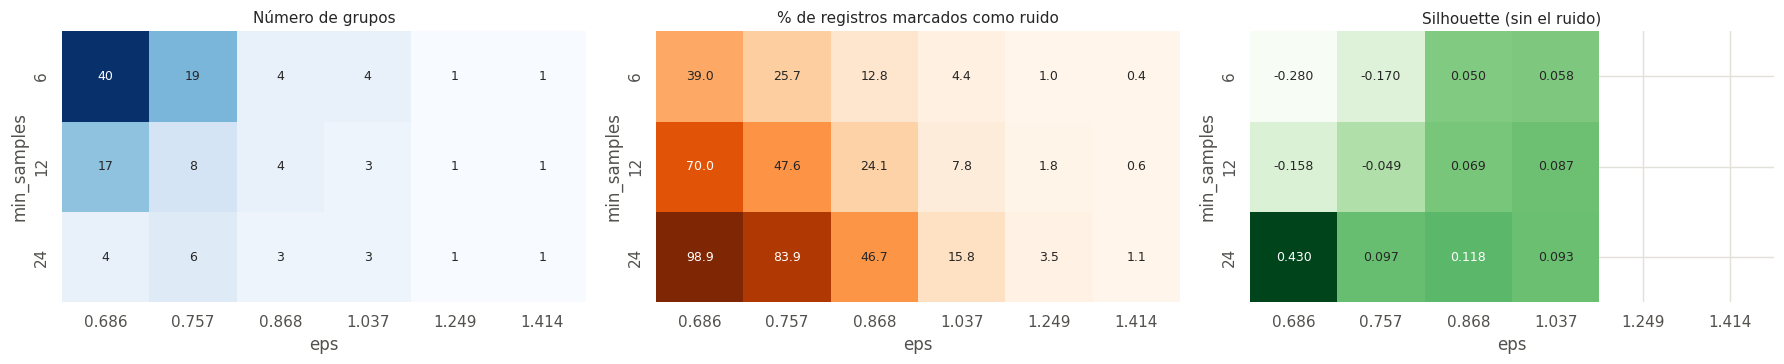

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
paneles = [("grupos", "Número de grupos", "d", "Blues"),
           ("% ruido", "% de registros marcados como ruido", ".1f", "Oranges"),
           ("Silhouette", "Silhouette (sin el ruido)", ".3f", "Greens")]
for ax, (columna, titulo, formato, mapa) in zip(axes, paneles):
    matriz = tabla_db[columna].unstack("eps")
    sns.heatmap(matriz, annot=True, fmt=formato, cmap=mapa, cbar=False, ax=ax,
                annot_kws={"fontsize": 9})
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

**Lectura del resultado.**

- El gráfico de distancia al k-ésimo vecino no tiene codo: la distancia crece de forma
  continua entre 0,5 y 1,4 y solo se dispara en el último 2 % de los registros, que corresponde
  a registros extremos aislados y no a un límite entre grupos.
- Con `eps` pequeño (percentiles 10 y 25), DBSCAN fragmenta los datos en muchos grupos
  diminutos y deja entre el 26 % y el 99 % de los registros como ruido; con `eps` grande
  (percentiles 90 y 95) une todo en un solo grupo. No hay un rango de `eps` en que aparezcan
  grupos estables, como ocurriría con grupos densos separados por zonas vacías.
- La configuración seleccionada (`eps` = 1,037, `min_samples` = 12) forma **tres grupos de tamaño
  parecido** (2.945, 2.979 y 3.291 registros) y deja el 7,9 % como ruido, con un Silhouette de
  0,087 aun sin contar el ruido. Tres es exactamente el número de niveles de `Activity Level`:
  con este radio, los registros de un mismo nivel de actividad se conectan entre sí, pero el
  salto de ≈ 1,2 desviaciones estándar entre niveles no alcanza a cubrirse. El apartado 6.4
  confirma esta lectura.

### 4.4 Configuraciones seleccionadas

In [21]:
etiquetas_finales = {
    "K-Means": etiquetas_km[k_km],
    "Jerárquico": etiquetas_jer[mejor_jer],
    "DBSCAN": etiquetas_db[mejor_db],
}
configuraciones = {
    "K-Means": f"k = {k_km}, init = k-means++, n_init = 10",
    "Jerárquico": f"enlace = {mejor_jer[0]}, k = {mejor_jer[1]}",
    "DBSCAN": f"eps = {mejor_db[0]}, min_samples = {mejor_db[1]}",
}

resumen = pd.DataFrame({nombre: indices_validacion(X_valores, etiquetas)
                        for nombre, etiquetas in etiquetas_finales.items()}).T
resumen = resumen.astype(float)
resumen["grupos"] = resumen["grupos"].astype(int)
resumen.insert(0, "configuración", pd.Series(configuraciones))
resumen["registros por grupo"] = pd.Series({nombre: tamanos_grupos(etiquetas)
                                            for nombre, etiquetas in etiquetas_finales.items()})
resumen

,configuración,grupos,% grupo menor,% ruido,Silhouette,Calinski-Harabasz,Davies-Bouldin,registros por grupo
K-Means,"k = 2, init = k-means++, n_init = 10",2,46.9000,0.0000,0.1285,1431.1676,2.5431,"G0: 5310, G1: 4690"
Jerárquico,"enlace = ward, k = 2",2,48.1700,0.0000,0.0809,840.0916,3.3317,"G0: 5183, G1: 4817"
DBSCAN,"eps = 1.037, min_samples = 12",3,29.4500,7.8500,0.0866,1038.5006,3.3447,"ruido: 785, G0: 2945, G1: 2979, G2: 3291"


---

## 5. Interpretación de los grupos

Se interpreta la solución de **K-Means**, por tres razones: asigna todos los registros a un
grupo (DBSCAN deja registros sin asignar como ruido), sus centroides resumen cada grupo en los
valores de las variables, y es el algoritmo que un sistema de segmentación usaría en la
práctica para asignar a un usuario nuevo al grupo de su centroide más cercano.

El perfil se calcula en **unidades originales** (bpm, %, pasos, horas y escala de estrés),
sobre el conjunto limpio sin transformar, para que cada grupo pueda describirse en términos
del mundo real. El mapa de calor complementa la tabla con los centroides en Z-score: un valor
de +1 indica que el grupo está, en promedio, una desviación estándar por sobre la media del
conjunto en esa variable.

In [22]:
grupos_km = pd.Series(etiquetas_finales["K-Means"], index=limpio.index, name="Grupo")
MEDIAS = ["Heart Rate (BPM)", "Blood Oxygen Level (%)", "Sleep Duration (hours)", "Stress Level"]

perfil = limpio[MEDIAS].groupby(grupos_km).mean()
perfil.insert(0, "Step Count (mediana)", limpio["Step Count"].groupby(grupos_km).median())
perfil.insert(0, "% registros", grupos_km.value_counts(normalize=True).sort_index() * 100)
perfil.insert(0, "registros", grupos_km.value_counts().sort_index())
actividad_grupo = pd.crosstab(grupos_km, limpio["Activity Level"], normalize="index")[ORDEN_ACTIVIDAD]
perfil = perfil.join(actividad_grupo.mul(100).add_prefix("% "))

total = pd.Series({
    "registros": len(limpio), "% registros": 100.0,
    "Step Count (mediana)": limpio["Step Count"].median(),
    **limpio[MEDIAS].mean().to_dict(),
    **(limpio["Activity Level"].value_counts(normalize=True)[ORDEN_ACTIVIDAD] * 100)
      .add_prefix("% ").to_dict(),
})
perfil.index = [f"Grupo {g}" for g in perfil.index]
perfil.loc["Total"] = total[perfil.columns]
perfil["registros"] = perfil["registros"].astype(int)

perfil.style.format(precision=2, formatter={"registros": "{:d}", "Step Count (mediana)": "{:,.0f}"})

,registros,% registros,Step Count (mediana),Heart Rate (BPM),Blood Oxygen Level (%),Sleep Duration (hours),Stress Level,% Sedentary,% Active,% Highly Active
Grupo 0,5310,53.10,"5,058",74.66,98.28,6.49,5.52,66.52,33.48,0.00
Grupo 1,4690,46.90,"4,828",76.31,97.36,6.52,5.38,0.02,31.71,68.27
Total,10000,100.00,"4,963",75.43,97.85,6.51,5.45,35.33,32.65,32.02


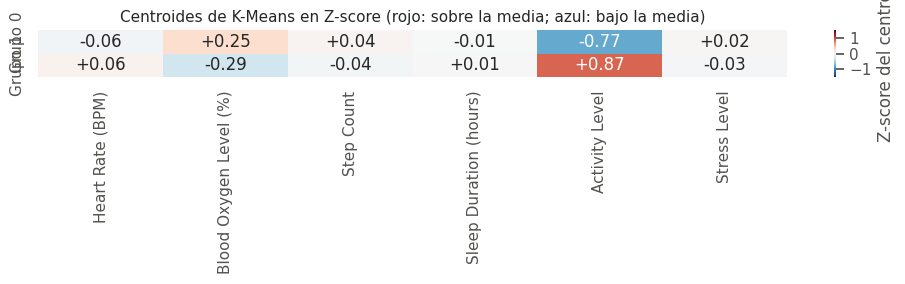

In [23]:
centroides_z = X.groupby(grupos_km).mean()
centroides_z.index = [f"Grupo {g}" for g in centroides_z.index]

fig, ax = plt.subplots(figsize=(10, 0.7 * len(centroides_z) + 1.6))
sns.heatmap(centroides_z, annot=True, fmt="+.2f", cmap="RdBu_r", vmin=-1.5, vmax=1.5, center=0,
            cbar_kws={"label": "Z-score del centroide"}, ax=ax)
ax.set_title("Centroides de K-Means en Z-score (rojo: sobre la media; azul: bajo la media)")
plt.tight_layout()
plt.show()

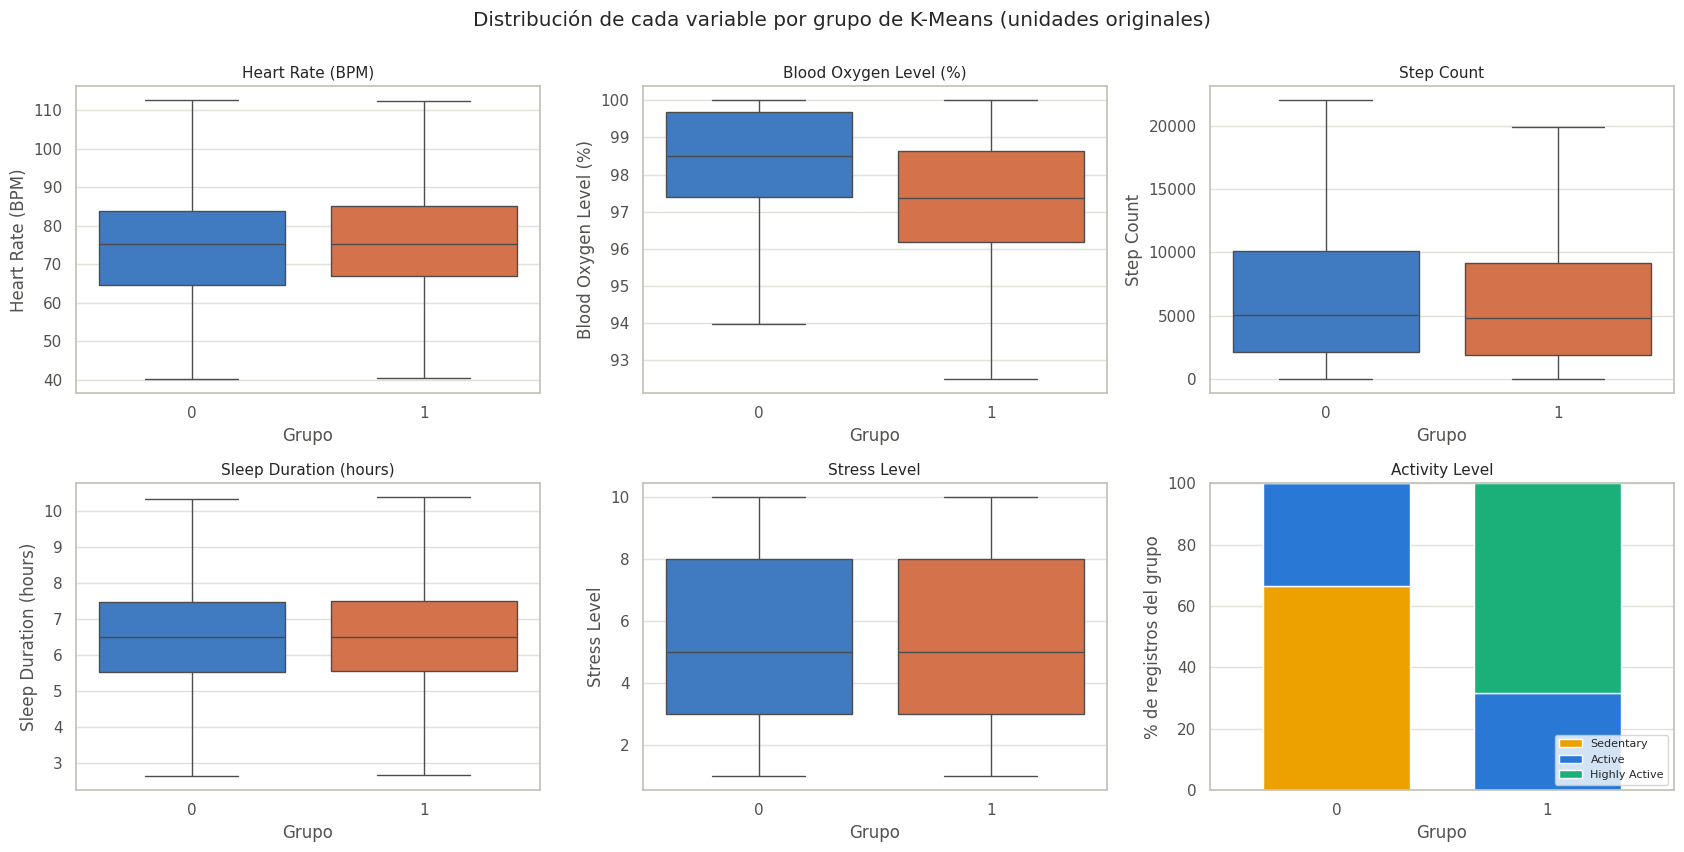

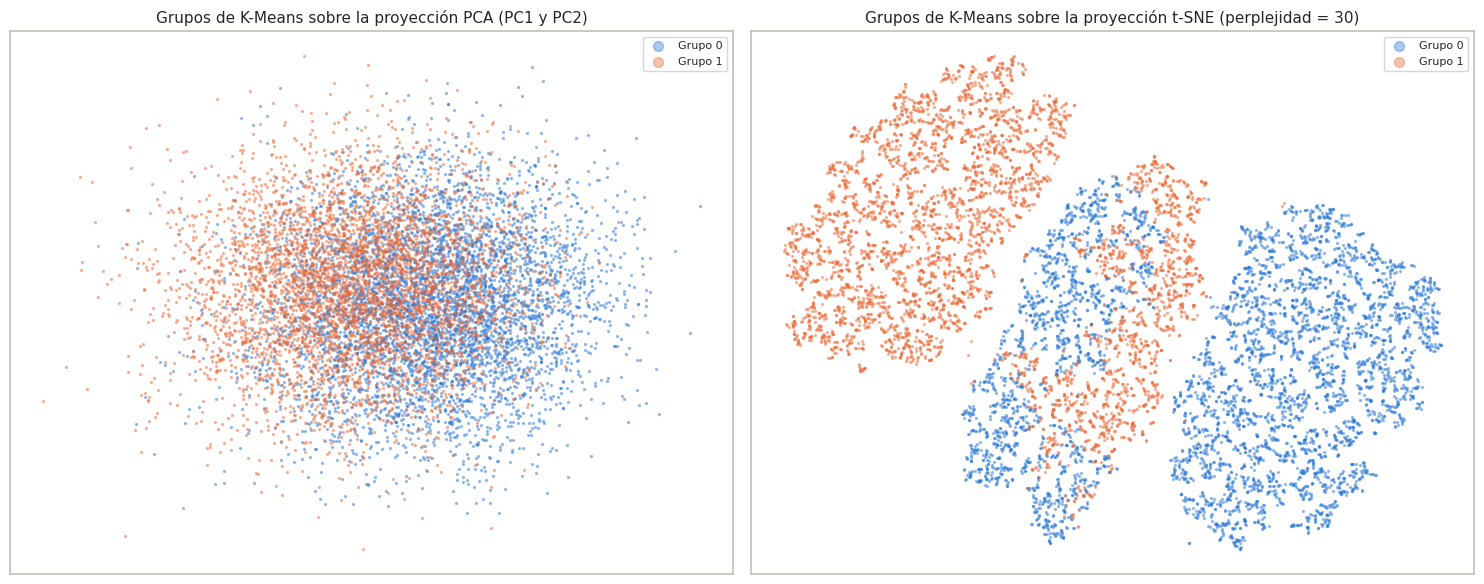

In [24]:
etiquetas = etiquetas_finales["K-Means"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, variable in zip(axes.flat, CONTINUAS + ["Stress Level"]):
    sns.boxplot(x=grupos_km, y=limpio[variable], hue=grupos_km, palette=PALETA_GRUPOS[:k_km],
                legend=False, showfliers=False, ax=ax)
    ax.set_xlabel("Grupo")
    ax.set_title(variable)
ax = axes.flat[5]
(actividad_grupo * 100).plot(kind="bar", stacked=True, ax=ax,
                             color=[COLORES_ACTIVIDAD[n] for n in ORDEN_ACTIVIDAD], width=0.7)
ax.set_xlabel("Grupo")
ax.set_ylabel("% de registros del grupo")
ax.set_title("Activity Level")
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Distribución de cada variable por grupo de K-Means (unidades originales)", y=1.0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (proyeccion, titulo) in zip(axes, [(proyeccion_pca[:, :2], "PCA (PC1 y PC2)"),
                                          (proyeccion_tsne, f"t-SNE (perplejidad = {PERPLEJIDAD})")]):
    for g in range(k_km):
        m = etiquetas == g
        ax.scatter(proyeccion[m, 0], proyeccion[m, 1], s=2, alpha=0.4, color=PALETA_GRUPOS[g],
                   label=f"Grupo {g}")
    ax.set_title(f"Grupos de K-Means sobre la proyección {titulo}")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(markerscale=5, fontsize=8)
plt.tight_layout()
plt.show()

### Descripción de los grupos

| Grupo | Registros | Qué lo distingue | Lectura en el mundo real |
| --- | --- | --- | --- |
| **Grupo 0** | 5.310 (53,1 %) | Reúne a todos los registros `Sedentary` salvo uno (66,5 % del grupo) y a poco más de la mitad de los `Active` (33,5 %); ningún `Highly Active`. Saturación de oxígeno algo mayor que el promedio (98,3 % frente a 97,8 %) | **Mediciones de baja actividad declarada**: usuarios sedentarios o moderadamente activos |
| **Grupo 1** | 4.690 (46,9 %) | Reúne a todos los registros `Highly Active` (68,3 % del grupo) y al resto de los `Active` (31,7 %). Saturación de oxígeno algo menor (97,4 %) | **Mediciones de alta actividad declarada**: usuarios activos o muy activos |

**En las demás variables los dos grupos son prácticamente iguales**: pulso medio de 74,7 y
76,3 bpm, sueño de 6,49 y 6,52 horas, estrés de 5,5 y 5,4, y una mediana de 5.058 y 4.828 pasos.
Los diagramas de caja de estas variables se superponen casi por completo.

**Lectura crítica.** La segmentación tiene una interpretación de negocio aparentemente clara
(usuarios de baja y de alta actividad), pero no resiste un examen:

1. **Es la partición de una sola variable.** El grupo queda determinado casi por completo por
   `Activity Level`; K-Means solo tuvo que decidir de qué lado dejar a los registros `Active`.
   No se descubrió una combinación nueva de variables, sino una categoría que ya estaba en los
   datos.
2. **Contradice las mediciones del propio dispositivo.** Si el Grupo 1 reuniera de verdad a los
   usuarios más activos, debería registrar más pasos; sin embargo, su mediana de pasos es
   incluso algo menor que la del Grupo 0. En datos reales, la actividad declarada y los pasos
   medidos estarían relacionados; aquí son independientes, como ya se observó en la EP1.
3. **La diferencia de oxigenación tampoco tiene explicación fisiológica.** En personas sanas, la
   actividad física habitual no reduce la saturación de oxígeno. La diferencia de ≈ 0,9 puntos
   porcentuales proviene de dónde K-Means trazó el corte: la oxigenación es la continua más
   asimétrica (techo en 100 %), lo que la hace la más favorable para dividir la nube. El
   apartado 6.3 muestra que el mismo corte, con la misma calidad, aparece en datos con las
   columnas permutadas, es decir, sin ninguna relación entre variables.

En consecuencia, la tabla describe correctamente la partición, pero **no debe usarse como una
segmentación de usuarios**: separar por actividad declarada se puede hacer directamente con la
variable `Activity Level`, sin un modelo de agrupamiento.

---

## 6. Validación de los agrupamientos

Se usan tres **índices de validación interna**, que evalúan la partición solo a partir de los
datos, sin una etiqueta verdadera con la cual compararla:

| Índice | Qué mide | Rango | Mejor valor |
| --- | --- | --- | --- |
| Silhouette | Para cada registro compara su distancia media a los registros de su grupo (*a*) con la distancia media al grupo vecino más cercano (*b*): *s* = (*b* − *a*) / máx(*a*, *b*). Se promedia sobre todos los registros | −1 a 1 | Mayor |
| Calinski-Harabasz | Razón entre la dispersión entre grupos y la dispersión dentro de los grupos, corregida por el número de grupos y de registros | 0 a ∞ | Mayor |
| Davies-Bouldin | Promedio, sobre los grupos, de la peor razón entre la dispersión interna de dos grupos y la distancia entre sus centroides | 0 a ∞ | Menor |

Para el Silhouette existe una escala de interpretación de referencia (Kaufman y Rousseeuw,
1990):

| Silhouette medio | Interpretación |
| --- | --- |
| 0,71 a 1,00 | Estructura fuerte |
| 0,51 a 0,70 | Estructura razonable |
| 0,26 a 0,50 | Estructura débil, que puede ser artificial |
| 0,25 o menos | Sin estructura sustancial |

En DBSCAN los índices se calculan sin los registros de ruido, lo que los favorece: el
porcentaje de ruido debe leerse junto con ellos.

### 6.1 Índices de las configuraciones seleccionadas

In [25]:
def escala_kaufman(valor):
    if pd.isna(valor):
        return "no calculable"
    if valor > 0.70:
        return "estructura fuerte"
    if valor > 0.50:
        return "estructura razonable"
    if valor > 0.25:
        return "estructura débil"
    return "sin estructura sustancial"


tabla_validacion = resumen[["configuración", "grupos", "% ruido"] + INDICES].copy()
tabla_validacion["lectura del Silhouette"] = tabla_validacion["Silhouette"].map(escala_kaufman)
tabla_validacion

,configuración,grupos,% ruido,Silhouette,Calinski-Harabasz,Davies-Bouldin,lectura del Silhouette
K-Means,"k = 2, init = k-means++, n_init = 10",2,0.0000,0.1285,1431.1676,2.5431,sin estructura sustancial
Jerárquico,"enlace = ward, k = 2",2,0.0000,0.0809,840.0916,3.3317,sin estructura sustancial
DBSCAN,"eps = 1.037, min_samples = 12",3,7.8500,0.0866,1038.5006,3.3447,sin estructura sustancial


### 6.2 Silueta por registro (K-Means)

El promedio del Silhouette puede ocultar diferencias entre grupos. El gráfico de silueta
muestra el valor de cada registro, ordenado dentro de su grupo: un grupo bien definido tiene
la mayoría de sus registros con silueta alta, mientras que los valores negativos indican
registros que están, en promedio, más cerca de otro grupo que del propio.

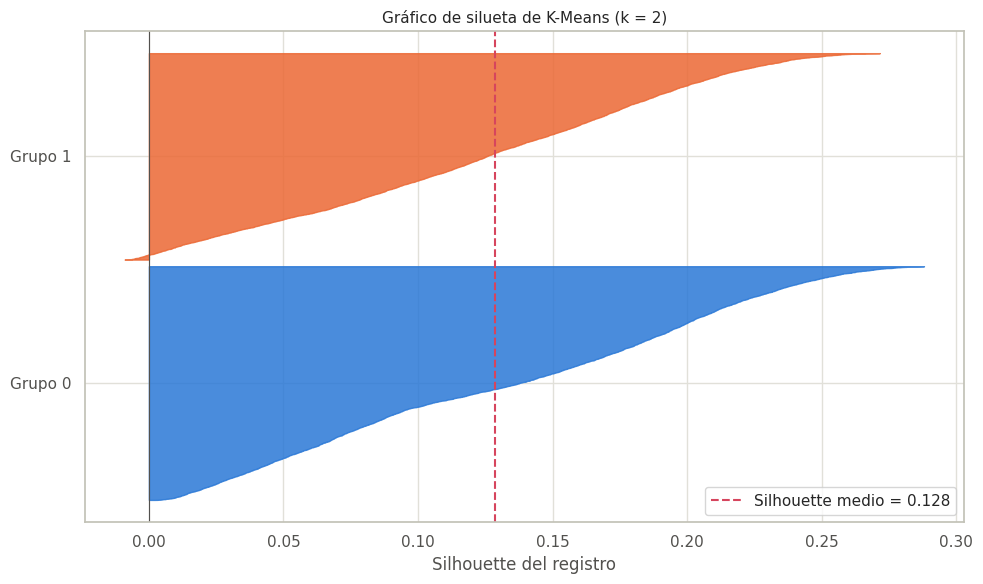

Registros con silueta negativa en total: 1.1 %


,registros,Silhouette medio,% con silueta negativa
Grupo 0,5310,0.1336,0.0000
Grupo 1,4690,0.1226,2.4094


In [26]:
etiquetas = etiquetas_finales["K-Means"]
silueta = silhouette_samples(X_valores, etiquetas)

fig, ax = plt.subplots(figsize=(10, 6))
base, centros = 0, []
for g in range(k_km):
    valores = np.sort(silueta[etiquetas == g])
    ax.fill_betweenx(np.arange(base, base + len(valores)), 0, valores,
                     color=PALETA_GRUPOS[g], alpha=0.85)
    centros.append(base + len(valores) / 2)
    base += len(valores) + 150
ax.axvline(silueta.mean(), color="#d6455d", ls="--", label=f"Silhouette medio = {silueta.mean():.3f}")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(centros, [f"Grupo {g}" for g in range(k_km)])
ax.set_xlabel("Silhouette del registro")
ax.set_title(f"Gráfico de silueta de K-Means (k = {k_km})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

silueta_grupo = pd.DataFrame({
    "registros": pd.Series(etiquetas).value_counts().sort_index(),
    "Silhouette medio": pd.Series(silueta).groupby(etiquetas).mean(),
    "% con silueta negativa": pd.Series(silueta < 0).groupby(etiquetas).mean() * 100,
})
silueta_grupo.index = [f"Grupo {g}" for g in silueta_grupo.index]
print(f"Registros con silueta negativa en total: {(silueta < 0).mean() * 100:.1f} %")
silueta_grupo

### 6.3 Valores de referencia: ¿qué Silhouette tendría un conjunto sin grupos?

Calinski-Harabasz y Davies-Bouldin no tienen una escala absoluta, y la escala del Silhouette
es solo orientativa. Para juzgar los índices se necesita saber qué valores producen los mismos
algoritmos cuando **no hay grupos que encontrar**, y cuando **sí los hay**. Se construyen dos
referencias, con la misma lógica de verificación usada en la EP3:

1. **Referencia sin estructura (permutación).** Se generan 10 versiones del conjunto en que
   cada columna se permuta por separado: cada variable conserva exactamente su distribución
   (incluidos los niveles discretos de `Activity Level` y `Stress Level` y la forma de `Step
   Count`), pero se destruye cualquier relación entre variables. Sobre cada versión se aplica
   el mismo algoritmo con la misma configuración. Si los índices reales no superan a los de
   estas réplicas, los grupos no provienen de combinaciones de valores que se repitan en los
   datos, sino de la forma de cada variable por separado.
2. **Control positivo.** Se genera un conjunto sintético del mismo tamaño y con seis variables
   en el que sí existen cuatro grupos (`make_blobs`). El mismo procedimiento de selección debe
   recuperar `k = 4` con índices altos, lo que demuestra que es capaz de detectar grupos
   cuando existen.

In [27]:
N_PERMUTACIONES = 10


def ajustar_kmeans(datos):
    return KMeans(n_clusters=k_km, n_init=10, random_state=SEMILLA).fit_predict(datos)


def ajustar_jerarquico(datos):
    return fcluster(linkage(datos, method=mejor_jer[0]), t=mejor_jer[1], criterion="maxclust") - 1


def ajustar_dbscan(datos):
    return DBSCAN(eps=mejor_db[0], min_samples=mejor_db[1]).fit_predict(datos)


AJUSTES = {"K-Means": ajustar_kmeans, "Jerárquico": ajustar_jerarquico, "DBSCAN": ajustar_dbscan}

generador = np.random.default_rng(SEMILLA)
replicas = [permutar_columnas(X_valores, generador) for _ in range(N_PERMUTACIONES)]

filas = []
for nombre, ajustar in AJUSTES.items():
    inicio = time.perf_counter()
    for i, datos in enumerate(replicas):
        filas.append({"algoritmo": nombre, "réplica": i, **indices_validacion(datos, ajustar(datos))})
    print(f"{nombre:<11}: {N_PERMUTACIONES} réplicas evaluadas en {time.perf_counter() - inicio:.0f} s")
nulo = pd.DataFrame(filas)

comparacion = []
for nombre in AJUSTES:
    referencia = nulo[nulo["algoritmo"] == nombre]
    fila = {"algoritmo": nombre}
    for indice in INDICES:
        fila[f"{indice} real"] = resumen.loc[nombre, indice]
        fila[f"{indice} sin estructura"] = (f"{referencia[indice].mean():.3f} ± "
                                            f"{referencia[indice].std():.3f}")
    fila["grupos en las réplicas"] = f"{referencia['grupos'].mean():.1f}"
    fila["% ruido en las réplicas"] = f"{referencia['% ruido'].mean():.1f}"
    comparacion.append(fila)

pd.DataFrame(comparacion).set_index("algoritmo").T

K-Means    : 10 réplicas evaluadas en 11 s


Jerárquico : 10 réplicas evaluadas en 39 s


DBSCAN     : 10 réplicas evaluadas en 13 s


algoritmo,K-Means,Jerárquico,DBSCAN
Silhouette real,0.1285,0.0809,0.0866
Silhouette sin estructura,0.129 ± 0.001,0.096 ± 0.008,0.087 ± 0.001
Calinski-Harabasz real,1431.1676,840.0916,1038.5006
Calinski-Harabasz sin estructura,1441.697 ± 10.781,1017.118 ± 105.176,1034.361 ± 4.099
Davies-Bouldin real,2.5431,3.3317,3.3447
Davies-Bouldin sin estructura,2.537 ± 0.010,3.003 ± 0.144,3.348 ± 0.008
grupos en las réplicas,2.0,2.0,3.0
% ruido en las réplicas,0.0,0.0,7.6


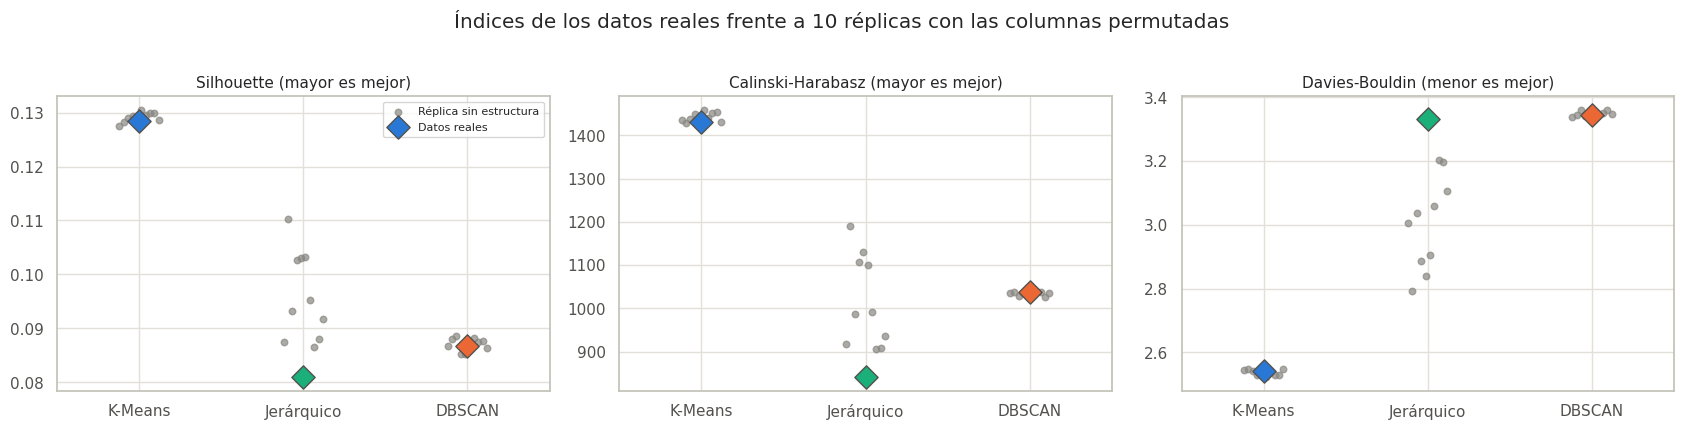

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, indice in zip(axes, INDICES):
    for posicion, nombre in enumerate(AJUSTES):
        valores = nulo.loc[nulo["algoritmo"] == nombre, indice].dropna()
        ax.scatter(np.full(len(valores), posicion) + np.linspace(-0.12, 0.12, len(valores)),
                   valores, color=COLORES["Referencia"], s=22, alpha=0.7,
                   label="Réplica sin estructura" if posicion == 0 else None)
        ax.scatter(posicion, resumen.loc[nombre, indice], color=COLORES[nombre], s=140,
                   marker="D", edgecolor="#52514e", zorder=3,
                   label="Datos reales" if posicion == 0 else None)
    ax.set_xticks(range(len(AJUSTES)), list(AJUSTES))
    ax.set_xlim(-0.5, len(AJUSTES) - 0.5)
    ax.set_title(indice + (" (menor es mejor)" if indice == "Davies-Bouldin" else " (mayor es mejor)"))
axes[0].legend(fontsize=8)
fig.suptitle("Índices de los datos reales frente a 10 réplicas con las columnas permutadas", y=1.02)
plt.tight_layout()
plt.show()

Control positivo: el procedimiento selecciona k = 4 (grupos verdaderos: 4), Silhouette = 0.522, ARI = 0.997


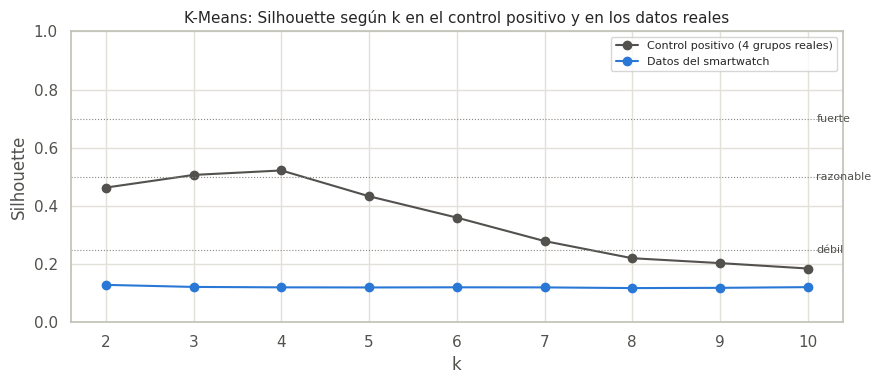

,grupos,% grupo menor,% ruido,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI con los grupos verdaderos
k,,,,,,,
2,2,49.9600,0.0000,0.4630,10618.1416,0.9445,0.4979
3,3,25.0000,0.0000,0.5064,12027.5638,0.7124,0.7127
4,4,24.9900,0.0000,0.5218,15558.7579,0.7430,0.9971
5,5,12.3600,0.0000,0.4330,12729.8451,1.0835,0.9098
6,6,12.0300,0.0000,0.3597,11084.9920,1.2980,0.8149
7,7,11.9500,0.0000,0.2791,10108.3809,1.4786,0.7114
8,8,12.0000,0.0000,0.2201,9531.6897,1.6069,0.5987
9,9,7.9900,0.0000,0.2033,8591.2476,1.7060,0.5577
10,10,7.8500,0.0000,0.1847,7859.2756,1.7904,0.5158


In [29]:
X_control, y_control = make_blobs(n_samples=len(X_valores), n_features=len(VARIABLES), centers=4,
                                  cluster_std=2.0, random_state=SEMILLA)
X_control = StandardScaler().fit_transform(X_control)

filas = []
for k in K_RANGO:
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(X_control)
    filas.append({"k": k, **indices_validacion(X_control, etiquetas),
                  "ARI con los grupos verdaderos": adjusted_rand_score(y_control, etiquetas)})
tabla_control = pd.DataFrame(filas).set_index("k")
k_control = seleccionar(tabla_control)
print(f"Control positivo: el procedimiento selecciona k = {k_control} (grupos verdaderos: 4), "
      f"Silhouette = {tabla_control.loc[k_control, 'Silhouette']:.3f}, "
      f"ARI = {tabla_control.loc[k_control, 'ARI con los grupos verdaderos']:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla_control.index, tabla_control["Silhouette"], "o-", color="#52514e",
        label="Control positivo (4 grupos reales)")
ax.plot(tabla_km.index, tabla_km["Silhouette"], "o-", color=COLORES["K-Means"],
        label="Datos del smartwatch")
for limite, texto in [(0.70, "fuerte"), (0.50, "razonable"), (0.25, "débil")]:
    ax.axhline(limite, color=COLORES["Referencia"], lw=0.8, ls=":")
    ax.text(10.1, limite, texto, fontsize=8, va="center", color="#52514e")
ax.set_xlabel("k")
ax.set_xticks(list(K_RANGO))
ax.set_ylabel("Silhouette")
ax.set_ylim(0, 1)
ax.set_title("K-Means: Silhouette según k en el control positivo y en los datos reales")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

tabla_control

### 6.4 Origen de los grupos: ¿qué variable los define?

Por último, se mide cuánto coincide cada agrupamiento con cada variable por separado,
mediante el índice de Rand ajustado (ARI): un valor cercano a 1 indicaría que el algoritmo
solo "redescubrió" una variable que ya estaba en los datos, y no una combinación de varias.
Las continuas se dividen en cuartiles para poder compararlas. Además, se repite K-Means usando
solo las cuatro variables continuas, para ver si la estructura cambia sin las dos variables
discretas.

In [30]:
acuerdo = {}
for nombre, etiquetas in etiquetas_finales.items():
    fila = {}
    for variable in VARIABLES:
        referencia = limpio[variable]
        if variable in CONTINUAS:
            referencia = pd.qcut(referencia, 4, labels=False, duplicates="drop")
        fila[variable] = adjusted_rand_score(referencia, etiquetas)
    acuerdo[nombre] = fila

tabla_acuerdo = pd.DataFrame(acuerdo).T
tabla_acuerdo.columns = [f"ARI con {v}" + (" (cuartiles)" if v in CONTINUAS else "")
                         for v in VARIABLES]
tabla_acuerdo

,ARI con Heart Rate (BPM) (cuartiles),ARI con Blood Oxygen Level (%) (cuartiles),ARI con Step Count (cuartiles),ARI con Sleep Duration (hours) (cuartiles),ARI con Activity Level,ARI con Stress Level
K-Means,0.0015,0.0382,0.0007,-0.0000,0.4529,0.0001
Jerárquico,0.0004,0.0800,0.0026,0.0354,0.1344,0.0069
DBSCAN,0.0025,0.0051,0.0022,0.0031,0.8786,0.0002


In [31]:
X_continuas = X[CONTINUAS].to_numpy()

filas = []
for k in K_RANGO:
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(X_continuas)
    filas.append({"k": k, "Silhouette (solo continuas)": silhouette_score(X_continuas, etiquetas)})

sensibilidad = pd.DataFrame(filas).set_index("k")
sensibilidad["Silhouette (seis variables)"] = tabla_km["Silhouette"]
sensibilidad.T

k,2,3,4,5,6,7,8,9,10
Silhouette (solo continuas),0.1801,0.1692,0.1723,0.1789,0.1727,0.1701,0.1709,0.1694,0.1675
Silhouette (seis variables),0.1285,0.1214,0.1200,0.1196,0.1201,0.1198,0.1174,0.1183,0.1207


---

## 7. Juicio de la calidad del agrupamiento

Los índices del apartado 6 permiten juzgar la calidad en tres niveles: el valor de cada índice,
su comparación con conjuntos de estructura conocida y el origen de los grupos.

**1. Valor de los índices: los tres agrupamientos quedan en la categoría "sin estructura
sustancial".** El mejor Silhouette es el de K-Means (0,129), seguido de DBSCAN (0,087, aun
descontando el 7,9 % de ruido) y del jerárquico (0,081), todos lejos de 0,25. Los valores de
Davies-Bouldin, entre 2,5 y 3,3, indican que la dispersión interna de los grupos supera a la
distancia entre sus centroides, es decir, que los grupos se superponen. El gráfico de silueta
de K-Means muestra que casi ningún registro está mal asignado (1,1 % con silueta negativa),
pero tampoco claramente asignado: todos los registros tienen siluetas entre 0 y 0,29, lo que
significa que cada uno está casi a la misma distancia de su grupo que del otro.

**2. Comparación con las referencias: los grupos no superan a los de un conjunto sin
estructura.**

- Con las columnas permutadas, sin ninguna relación entre variables, K-Means obtiene un
  Silhouette de 0,129 ± 0,001, idéntico al real (0,1285), y DBSCAN uno de 0,087 ± 0,001, también
  idéntico, con el mismo número de grupos (3) y un ruido similar (7,6 %). El jerárquico obtiene
  en los datos reales un Silhouette **menor** que en las 10 réplicas (0,081 frente a
  0,096 ± 0,008). Calinski-Harabasz y Davies-Bouldin muestran lo mismo.
- En el control positivo, el mismo procedimiento sí encuentra la estructura: selecciona k = 4,
  el número correcto, con un Silhouette de 0,52 ("estructura razonable") y un ARI de 0,997 con
  los grupos verdaderos. Su curva de Silhouette tiene un máximo claro en k = 4, mientras que la
  de los datos reales es plana.

Juntas, las dos referencias descartan que el problema esté en el procedimiento: los algoritmos
detectan grupos cuando existen y, en este conjunto, producen los mismos índices que en datos
donde, por construcción, no hay relaciones entre variables.

**3. Origen de los grupos: una variable discreta y no perfiles de usuario.** El ARI muestra que
los grupos de DBSCAN reproducen casi exactamente los niveles de `Activity Level` (ARI = 0,88) y
que los de K-Means coinciden parcialmente con ella (0,45), mientras que con las demás variables
el ARI es prácticamente cero (como máximo 0,08, entre el jerárquico y la oxigenación). Esto
explica por qué la referencia por permutación produce los mismos índices: la permutación
conserva los tres niveles de actividad, que son la única "separación" del conjunto. Sin las
variables discretas, K-Means obtiene un Silhouette algo mayor (entre 0,17 y 0,18), pero
igualmente plano y sin un k preferido; el aumento se debe a que, en menos dimensiones, dividir
una nube sin estructura produce siluetas algo mayores, no a que aparezcan grupos.

**Juicio.** La calidad de los tres agrupamientos es **insuficiente**: sus índices corresponden a
la categoría "sin estructura sustancial", no superan a los de datos sin relaciones entre
variables y sus grupos solo reproducen una variable que ya estaba en el conjunto. De los tres,
K-Means obtiene los mejores valores en los tres índices (mayor Silhouette y Calinski-Harabasz,
menor Davies-Bouldin) y es el único que asigna todos los registros, por lo que sería el
algoritmo a elegir si hubiera que segmentar. Con estos datos, sin embargo, ninguna segmentación
aporta información que no se obtenga directamente de `Activity Level`.

---

## 8. Conclusiones

### Qué se hizo

- Se reconstruyó el conjunto limpio de la EP1 y se aplicaron tres filtros de selección de
  características: se descartó `User ID` por ser un identificador y se conservaron las seis
  variables biométricas, ninguna con baja variabilidad ni redundante.
- Se adaptó el preprocesamiento a algoritmos basados en distancias: Z-score para las seis
  variables, incluidas las ordinales, y transformación de Yeo-Johnson para la asimetría de
  `Step Count`.
- Se aplicaron dos técnicas de reducción de dimensionalidad: PCA, con análisis paralelo de Horn,
  y t-SNE, con tres perplejidades.
- Se aplicaron tres algoritmos de agrupamiento con exploración de hiperparámetros y una regla
  de selección común: K-Means (k de 2 a 10, inicialización y reinicios), jerárquico aglomerativo
  (tres enlaces y k de 2 a 10) y DBSCAN (18 combinaciones de `eps` y `min_samples`).
- Se validaron los agrupamientos con Silhouette, Calinski-Harabasz y Davies-Bouldin,
  contrastados con 10 réplicas sin estructura y con un control positivo, y se midió el acuerdo
  de cada agrupamiento con cada variable.

### Qué se encontró

1. **El conjunto no se puede comprimir.** Las seis componentes del PCA explican lo mismo
   (≈ 16,7 % cada una) y ninguna supera la referencia sin estructura.
2. **No existen grupos naturales de registros.** Los tres algoritmos obtienen un Silhouette entre
   0,08 y 0,13, en la categoría "sin estructura sustancial", igual o peor que en datos con las
   columnas permutadas.
3. **Las únicas separaciones visibles son un efecto de la codificación.** Las tres islas de t-SNE
   y los tres grupos de DBSCAN son los tres niveles de `Activity Level`; los dos grupos de
   K-Means separan la actividad declarada baja de la alta, sin diferencias reales en pulso,
   pasos, sueño ni estrés.
4. **El procedimiento funciona.** En el control positivo recupera los cuatro grupos verdaderos con
   un ARI de 0,997, de modo que la ausencia de grupos es una propiedad de los datos y no del
   método.

### Respuesta a la problemática de negocio

Con este conjunto **no es posible segmentar a los usuarios** en perfiles biométricos. La única
segmentación que producen los algoritmos (actividad declarada baja frente a alta) equivale a
filtrar por la variable `Activity Level` y, además, contradice las mediciones del propio
dispositivo: el grupo "más activo" no camina más. Usarla para personalizar recomendaciones o
alertas significaría tratar de forma distinta a usuarios cuyo estado biométrico es, en
promedio, el mismo.

### Limitación y recomendaciones

Este resultado cierra de forma coherente el proyecto: la EP1 mostró que las variables no están
correlacionadas, la EP3 que ninguna permite predecir a otra y la EP5 que tampoco se combinan en
grupos. Las tres conclusiones tienen la misma causa, ya señalada en la EP1: el **origen simulado
del conjunto**, en el que cada variable se generó de forma independiente. Para que una
segmentación sea útil se recomienda:

1. **Trabajar con datos reales del dispositivo**, en los que existen relaciones fisiológicas
   (por ejemplo, entre pasos y nivel de actividad, o entre estrés y pulso en reposo).
2. **Agrupar usuarios y no mediciones**, resumiendo las mediciones de cada usuario (promedio,
   variabilidad y tendencia), ya que el conjunto contiene en promedio 2,7 mediciones por usuario.
3. **Mantener el protocolo de validación de este informe** (referencia por permutación y control
   positivo), para que cualquier segmentación futura pueda distinguirse de un corte arbitrario
   de una nube sin estructura.

---

### Referencias

- Anthropic. (2026). *Claude* (versión Opus 5.5) [Modelo de lenguaje de gran tamaño].
  https://claude.ai
- Caliński, T. y Harabasz, J. (1974). A dendrite method for cluster analysis.
  *Communications in Statistics, 3*(1), 1-27.
- Davies, D. L. y Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on
  Pattern Analysis and Machine Intelligence, 1*(2), 224-227.
- Ester, M., Kriegel, H.-P., Sander, J. y Xu, X. (1996). A density-based algorithm for
  discovering clusters in large spatial databases with noise. *Proceedings of the Second
  International Conference on Knowledge Discovery and Data Mining (KDD-96)*, 226-231.
- Horn, J. L. (1965). A rationale and test for the number of factors in factor analysis.
  *Psychometrika, 30*(2), 179-185.
- Kaufman, L. y Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster
  analysis*. Wiley.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of
  Machine Learning Research, 12*, 2825-2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation
  of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53-65.
- Sander, J., Ester, M., Kriegel, H.-P. y Xu, X. (1998). Density-based clustering in spatial
  databases: The algorithm GDBSCAN and its applications. *Data Mining and Knowledge
  Discovery, 2*(2), 169-194.
- van der Maaten, L. y Hinton, G. (2008). Visualizing data using t-SNE. *Journal of Machine
  Learning Research, 9*, 2579-2605.
- Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in
  Python. *Nature Methods, 17*, 261-272.
- Yeo, I.-K. y Johnson, R. A. (2000). A new family of power transformations to improve
  normality or symmetry. *Biometrika, 87*(4), 954-959.